# Data exploration

The raw surveillance data before preprocessing:
- **ERVISS** (pyerviss): ILI and ARI incidence of the EU/EEA countries, all ages, from season 2014/15
- **ERVISS** positivity: % positive tests for influenza, RSV and SARS-CoV-2
- **WHO FluID**: ILI and ARI of Switzerland and the UK regions, which are not in ERVISS

ILI and ARI are analysed separately: set `TARGET` and run the notebook once for each.

* Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

* Directories

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

TARGET = "ILI"         # "ILI" or "ARI"

RAW = ROOT / "target-data/raw"
OUT_DIR = ROOT / f"results/exploration/data/{TARGET.lower()}"
FIG_DIR = ROOT / f"figures/exploration/data/{TARGET.lower()}"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

FIRST_SEASON = 2014
SEASON_START = 40
SEASON_END = 20
MAX_SEASON_WEEKS = 34
VALID_SHARE = 0.5
MIN_TESTS = 10         # positivity from fewer tests is unreliable

FLUID_COUNTRIES = {
    "Switzerland": "CH",
    "United Kingdom, England": "GB-ENG",
    "United Kingdom, Northern Ireland": "GB-NIR",
    "United Kingdom, Scotland": "GB-SCT",
    "United Kingdom, Wales": "GB-WLS",
}
GB_REGIONS = ["GB-ENG", "GB-NIR", "GB-SCT", "GB-WLS"]

## 1. Load the data

In [3]:
erviss = pd.read_csv(RAW / f"erviss/{TARGET.lower()}_total.csv", parse_dates=["date"])
erviss["source"] = "ERVISS"
pos = pd.read_csv(RAW / "erviss/positivity.csv", parse_dates=["date"])
who = pd.read_csv(RAW / "who/fluid_epi.csv", low_memory=False)

print(f"ERVISS {TARGET}: {erviss.shape}, positivity: {pos.shape}, WHO FluID: {who.shape}")
erviss.head()

ERVISS ILI: (13018, 9), positivity: (30739, 12), WHO FluID: (14551, 38)


,indicator,country,country_code,year_week,date,age,value,unit,source
0,ili,Austria,AT,2014-W40,2014-10-05,total,589.6,"per 100,000 population",ERVISS
1,ili,Austria,AT,2014-W41,2014-10-12,total,547.3,"per 100,000 population",ERVISS
2,ili,Austria,AT,2014-W42,2014-10-19,total,768.8,"per 100,000 population",ERVISS
3,ili,Austria,AT,2014-W43,2014-10-26,total,696.1,"per 100,000 population",ERVISS
4,ili,Austria,AT,2014-W44,2014-11-02,total,762.6,"per 100,000 population",ERVISS


### WHO FluID: what is in the file
How Switzerland and the UK are named, which age groups exist and which columns are filled.

In [4]:
# target-data/raw/ keeps only Switzerland and the UK; the full FluID (all countries) is in .sources/ after a download
FULL = ROOT / ".sources/who/fluid_epi.csv"
if FULL.exists():
    full = pd.read_csv(FULL, low_memory=False, usecols=["WHOREGION", "COUNTRY_CODE", "COUNTRY_AREA_TERRITORY"])
    print("EUR countries in the full FluID:")
    print(full[full["WHOREGION"] == "EUR"][["COUNTRY_CODE", "COUNTRY_AREA_TERRITORY"]].drop_duplicates()
          .sort_values("COUNTRY_AREA_TERRITORY").to_string(index=False))

mask = who["COUNTRY_AREA_TERRITORY"].str.contains("Switzerland|United Kingdom", na=False)
who_sel = who[mask]

print("\nSelected countries:")
print(who_sel[["COUNTRY_CODE", "COUNTRY_AREA_TERRITORY"]].drop_duplicates().to_string(index=False))

print("\nAge groups:")
print(who_sel["AGEGROUP_CODE"].value_counts(dropna=False).to_string())

ili_cols = [f"{TARGET}_CASE", f"{TARGET}_OUTPATIENTS", f"{TARGET}_POP_COV"]
print(f"\n{TARGET} availability:")
print(who_sel.groupby(["COUNTRY_AREA_TERRITORY", "AGEGROUP_CODE"], dropna=False)
      .agg(first_year=("ISO_YEAR", "min"), last_year=("ISO_YEAR", "max"),
           rows=("ISO_WEEK", "size"),
           **{f"{c}_filled": (c, "count") for c in ili_cols})
      .to_string())

EUR countries in the full FluID:
COUNTRY_CODE                                                 COUNTRY_AREA_TERRITORY
         ALB                                                                Albania
         ARM                                                                Armenia
         AUT                                                                Austria
         AZE                                                             Azerbaijan
         BLR                                                                Belarus
         BEL                                                                Belgium
         BIH                                                 Bosnia and Herzegovina
         BGR                                                               Bulgaria
         HRV                                                                Croatia
         CYP                                                                 Cyprus
         CZE                               

### WHO FluID: Switzerland and UK regions
All-ages rows only (written both `ALL` and `All`), weeks with both cases and covered population.

In [5]:
case_col, pop_col = f"{TARGET}_CASE", f"{TARGET}_POP_COV"

fluid = who[who["COUNTRY_AREA_TERRITORY"].isin(FLUID_COUNTRIES)
            & (who["AGEGROUP_CODE"].str.upper() == "ALL")].copy()
fluid["country"] = fluid["COUNTRY_AREA_TERRITORY"]
fluid["country_code"] = fluid["COUNTRY_AREA_TERRITORY"].map(FLUID_COUNTRIES)
fluid["year_week"] = fluid["ISO_YEAR"].astype(str) + "-W" + fluid["ISO_WEEK"].astype(str).str.zfill(2)
fluid = fluid[["country", "country_code", "year_week", case_col, pop_col]].dropna()
fluid = fluid[fluid[pop_col] > 0]

fluid.groupby("country_code")["year_week"].agg(["min", "max", "count"])

,min,max,count
country_code,,,
CH,2009-W28,2026-W43,832
GB-ENG,2020-W01,2026-W43,241
GB-NIR,2020-W01,2026-W43,355
GB-SCT,2020-W01,2026-W40,352
GB-WLS,2020-W01,2026-W43,338


### United Kingdom as a whole
FluID has no data for the whole UK after 2013, so the cases and the covered population of the four regions
are summed and the incidence is computed from the sums. A week is kept only if all four regions reported it.

In [6]:
regions = fluid[fluid["country_code"].isin(GB_REGIONS)]
gb = (regions.groupby("year_week")
      .agg(n_regions=("country_code", "nunique"), cases=(case_col, "sum"), population=(pop_col, "sum"))
      .reset_index())

complete_weeks = gb["n_regions"] == len(GB_REGIONS)
print(f"GB: {complete_weeks.sum()} weeks with all 4 regions, {(~complete_weeks).sum()} weeks dropped")

gb = gb[complete_weeks].rename(columns={"cases": case_col, "population": pop_col})
gb["country"] = "United Kingdom (sum of regions)"
gb["country_code"] = "GB"
fluid = pd.concat([fluid, gb[fluid.columns]], ignore_index=True)

GB: 233 weeks with all 4 regions, 123 weeks dropped


### One table for all countries
FluID in the ERVISS format: incidence = cases / covered population × 100,000 (checked on SI),
date = Sunday of the ISO week, weeks from season 2014/15. `source` tells where a row comes from.

In [7]:
fluid["value"] = (fluid[case_col] / fluid[pop_col] * 100000).round(1)
fluid["date"] = pd.to_datetime(fluid["year_week"] + "-7", format="%G-W%V-%u")
fluid["indicator"] = TARGET.lower()
fluid["age"] = "total"
fluid["unit"] = "per 100,000 population"
fluid["source"] = "FluID"
fluid = fluid[erviss.columns]

first_date = pd.to_datetime(f"{FIRST_SEASON}-W40-7", format="%G-W%V-%u")
fluid = fluid[fluid["date"] >= first_date]

data = (pd.concat([erviss, fluid], ignore_index=True)
        .sort_values(["country_code", "date"])
        .reset_index(drop=True))

print(f"{TARGET}: {len(data)} rows, {data['country_code'].nunique()} countries, "
      f"{data['date'].min().date()} to {data['date'].max().date()}")
data.groupby("source")["country_code"].unique()

ILI: 15097 rows, 32 countries, 2014-10-05 to 2026-10-25


source
ERVISS    [AT, BE, CY, CZ, DK, EE, ES, FI, FR, GR, HR, H...
FluID              [CH, GB, GB-ENG, GB-NIR, GB-SCT, GB-WLS]
Name: country_code, dtype: object

## 2. Basic properties
- `data`: incidence of the chosen target, ERVISS + WHO FluID
- `pos`: ERVISS test positivity

### Size

In [8]:
dfs = {TARGET: data, "positivity": pos}

for name, d in dfs.items():
    print(f"{name:12} rows: {d.shape[0]:6}  columns: {d.shape[1]}")

ILI          rows:  15097  columns: 9
positivity   rows:  30739  columns: 12


### Columns

In [9]:
for name, d in dfs.items():
    print(f"{name}: {list(d.columns)}\n")

ILI: ['indicator', 'country', 'country_code', 'year_week', 'date', 'age', 'value', 'unit', 'source']

positivity: ['indicator', 'setting', 'pathogen', 'country', 'country_code', 'year_week', 'date', 'age', 'value', 'unit', 'tests', 'detections']



### Data types and non-null counts

In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15097 entries, 0 to 15096
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   indicator     15097 non-null  object        
 1   country       15097 non-null  object        
 2   country_code  15097 non-null  object        
 3   year_week     15097 non-null  object        
 4   date          15097 non-null  datetime64[ns]
 5   age           15097 non-null  object        
 6   value         15097 non-null  float64       
 7   unit          15097 non-null  object        
 8   source        15097 non-null  object        
dtypes: datetime64[ns](1), float64(1), object(7)
memory usage: 1.0+ MB


In [11]:
pos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30739 entries, 0 to 30738
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   indicator     30739 non-null  object        
 1   setting       30739 non-null  object        
 2   pathogen      30739 non-null  object        
 3   country       30739 non-null  object        
 4   country_code  30739 non-null  object        
 5   year_week     30739 non-null  object        
 6   date          30739 non-null  datetime64[ns]
 7   age           30739 non-null  object        
 8   value         30739 non-null  float64       
 9   unit          30739 non-null  object        
 10  tests         30739 non-null  int64         
 11  detections    30739 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(2), object(8)
memory usage: 2.8+ MB


### Text columns: unique values

In [12]:
for name, d in dfs.items():
    print(f"--- {name}")
    for col in d.select_dtypes(exclude=["number", "datetime"]).columns:
        values = d[col].unique()
        shown = sorted(values) if len(values) <= 10 else f"{sorted(values)[:5]} ..."
        print(f"{col}: {len(values)} unique -> {shown}")
    print()

--- ILI
indicator: 1 unique -> ['ili']
country: 32 unique -> ['Austria', 'Belgium', 'Croatia', 'Cyprus', 'Czechia'] ...
country_code: 32 unique -> ['AT', 'BE', 'CH', 'CY', 'CZ'] ...
year_week: 630 unique -> ['2014-W40', '2014-W41', '2014-W42', '2014-W43', '2014-W44'] ...
age: 1 unique -> ['total']
unit: 2 unique -> ['per 100,000 consultations', 'per 100,000 population']
source: 2 unique -> ['ERVISS', 'FluID']

--- positivity
indicator: 1 unique -> ['positivity']
setting: 2 unique -> ['hospital', 'primary care']
pathogen: 3 unique -> ['Influenza', 'RSV', 'SARS-CoV-2']
country: 30 unique -> ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus'] ...
country_code: 30 unique -> ['AT', 'BE', 'BG', 'CY', 'CZ'] ...
year_week: 645 unique -> ['2014-W25', '2014-W26', '2014-W27', '2014-W28', '2014-W29'] ...
age: 1 unique -> ['total']
unit: 1 unique -> ['%']



### Numeric columns: basic statistics

In [13]:
for name, d in dfs.items():
    print(f"--- {name}")
    print(d.describe().round(1), "\n")

--- ILI
                                date     value
count                          15097   15097.0
mean   2021-01-05 04:08:05.500430336     415.9
min              2014-10-05 00:00:00       0.0
25%              2017-12-31 00:00:00       3.3
50%              2021-03-14 00:00:00      26.5
75%              2024-01-21 00:00:00     154.8
max              2026-10-25 00:00:00  155763.0
std                              NaN    1898.6 

--- positivity
                                date    value    tests  detections
count                          30739  30739.0  30739.0     30739.0
mean   2022-11-11 09:33:43.396987392     12.8    196.3        26.7
min              2014-06-22 00:00:00      0.0      0.0         0.0
25%              2021-05-02 00:00:00      0.0     13.0         0.0
50%              2023-07-16 00:00:00      3.7     38.0         2.0
75%              2025-03-09 00:00:00     17.1    119.0        11.0
max              2026-10-25 00:00:00    100.0   5867.0      2743.0
std             

### Missing values

In [14]:
for name, d in dfs.items():
    print(f"{name:12} missing values: {d.isna().sum().sum()}")

ILI          missing values: 0


positivity   missing values: 0


### Duplicated

In [15]:
keys = {
    TARGET: ["country_code", "date"],
    "positivity": ["country_code", "date", "pathogen", "setting"],
}

for name, d in dfs.items():
    print(f"{name:12} duplicated rows: {d.duplicated().sum()}, "
          f"duplicated keys {keys[name]}: {d.duplicated(keys[name]).sum()}")

ILI          duplicated rows: 0, duplicated keys ['country_code', 'date']: 0
positivity   duplicated rows: 0, duplicated keys ['country_code', 'date', 'pathogen', 'setting']: 0


## 3. Coverage per country and season

### Season columns
A season runs from week 40 to week 20 of the next year; `season_week` = 1 for week 40. Weeks 21-39 have no season.

In [16]:
def add_season(d, date_col="date"):
    d = d.copy()
    iso = d[date_col].dt.isocalendar()
    week, year = iso["week"].astype(int), iso["year"].astype(int)
    in_season = (week >= SEASON_START) | (week <= SEASON_END)
    start_year = year.where(week >= SEASON_START, year - 1)
    season_start = pd.to_datetime(start_year.astype(str) + f"-W{SEASON_START}-7", format="%G-W%V-%u")
    d["season"] = (start_year.astype(str) + "/" + (start_year + 1).astype(str).str[-2:]).where(in_season)
    d["season_week"] = ((d[date_col] - season_start).dt.days // 7 + 1).where(in_season).astype("Int64")
    return d


data = add_season(data)
data[["country_code", "year_week", "date", "season", "season_week"]].head()

,country_code,year_week,date,season,season_week
0,AT,2014-W40,2014-10-05,2014/15,1
1,AT,2014-W41,2014-10-12,2014/15,2
2,AT,2014-W42,2014-10-19,2014/15,3
3,AT,2014-W43,2014-10-26,2014/15,4
4,AT,2014-W44,2014-11-02,2014/15,5


### Reported weeks per country and season

In [17]:
coverage = data.pivot_table(index="country_code", columns="season",
                            values="value", aggfunc="count").fillna(0).astype(int)
coverage.to_csv(OUT_DIR / "coverage_weeks.csv")
coverage

season,2014/15,2015/16,2016/17,2017/18,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25,2025/26,2026/27
country_code,,,,,,,,,,,,,
AT,26,26,27,28,25,26,23,27,26,27,27,27,4
BE,33,34,33,33,33,33,34,33,33,33,33,33,4
CH,33,34,33,33,33,24,30,33,33,33,33,33,4
CY,33,34,32,32,33,0,0,0,0,0,0,0,0
CZ,33,34,33,33,33,33,34,33,33,33,33,33,4
DK,32,34,32,33,32,32,34,33,33,33,33,33,4
EE,33,34,33,33,33,33,34,33,33,33,31,33,4
ES,33,34,33,33,33,33,0,0,0,33,33,33,4
FI,1,32,32,33,32,32,0,33,33,33,33,33,3


### Valid seasons
A season is valid if more than 50% of its weeks are reported (at least 17 of 33 or 18 of 34).
The current season, which has only just started, is left out.

In [18]:
def season_length(season):
    start = pd.to_datetime(f"{season[:4]}-W{SEASON_START}-7", format="%G-W%V-%u")
    end = pd.to_datetime(f"{int(season[:4]) + 1}-W{SEASON_END}-7", format="%G-W%V-%u")
    return (end - start).days // 7 + 1


finished = coverage.drop(columns=coverage.columns[-1])   # last column = current season
lengths = pd.Series({s: season_length(s) for s in finished.columns})

valid = pd.DataFrame({
    "valid_seasons": (finished.div(lengths, axis=1) > VALID_SHARE).sum(axis=1),
    "total_seasons": finished.shape[1],
})
valid["percent_valid"] = (100 * valid["valid_seasons"] / valid["total_seasons"]).round(1)

valid.sort_values("percent_valid")

,valid_seasons,total_seasons,percent_valid
country_code,,,
CY,5,12,41.7
GB-SCT,7,12,58.3
GB,7,12,58.3
GB-WLS,7,12,58.3
GB-NIR,7,12,58.3
GB-ENG,7,12,58.3
ES,9,12,75.0
PT,9,12,75.0
FI,10,12,83.3


## 4. Seasonal curves per country

One figure per country, one panel per finished season. Missing weeks are gaps in the line;
the title gives the number of reported weeks. Each panel has its own y-axis.

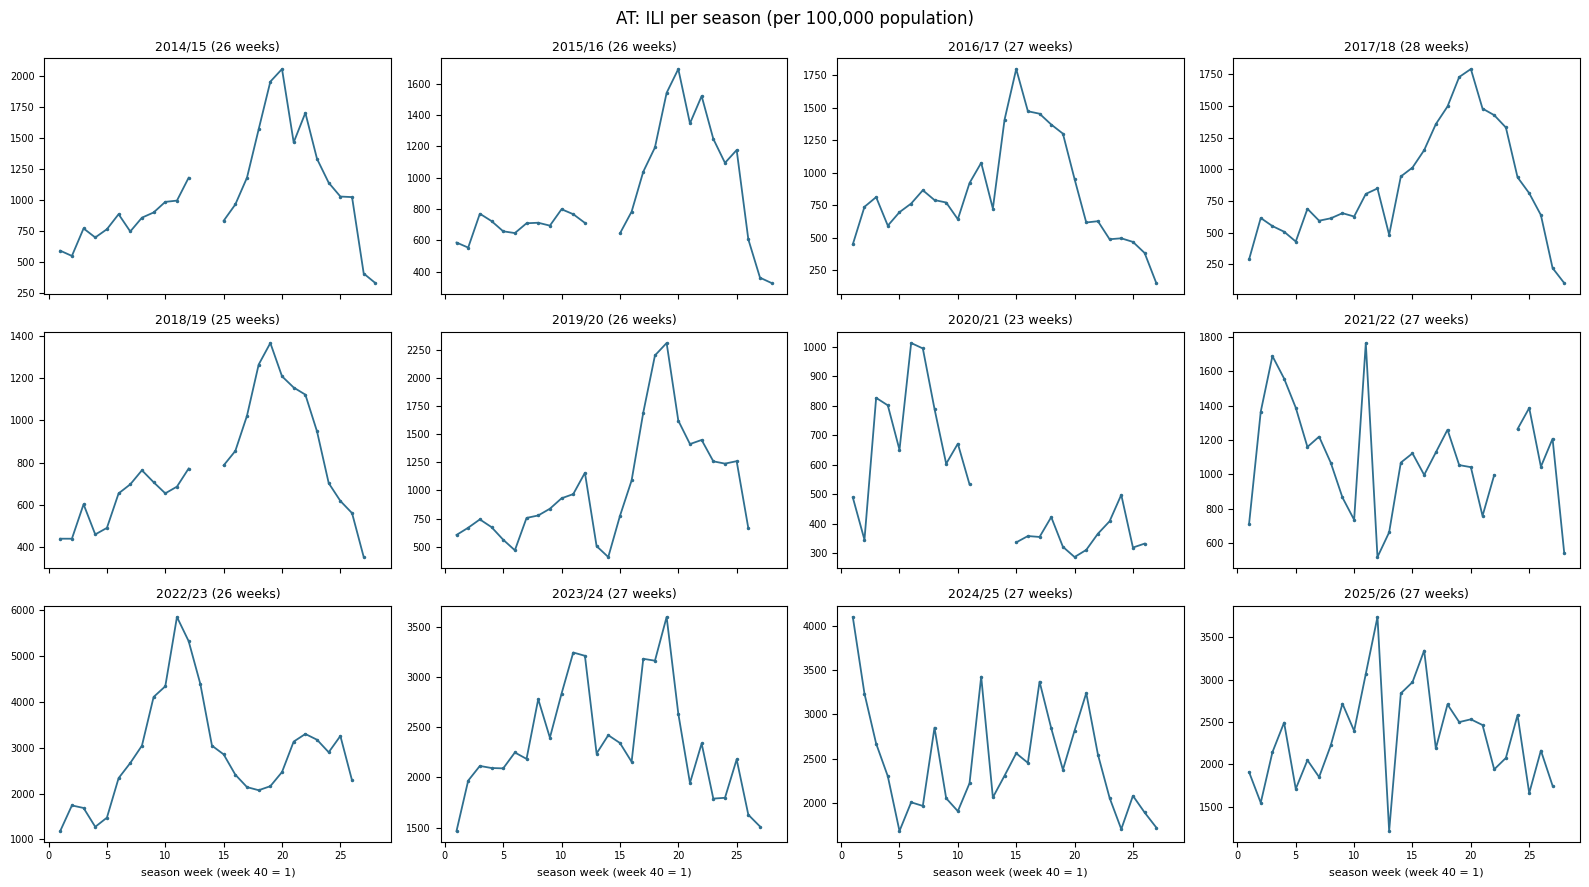

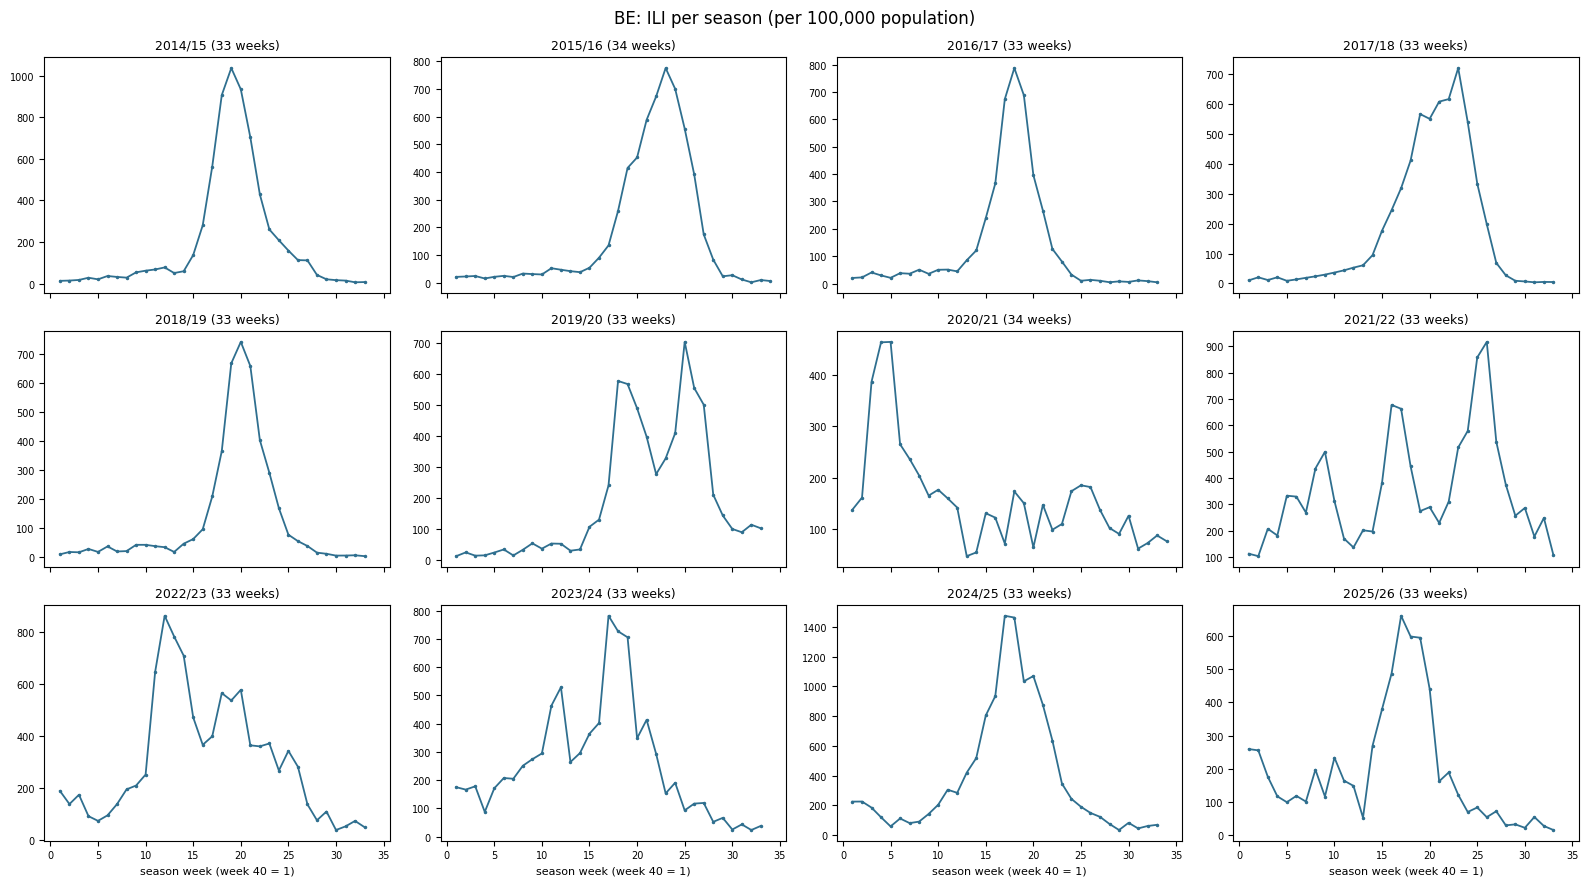

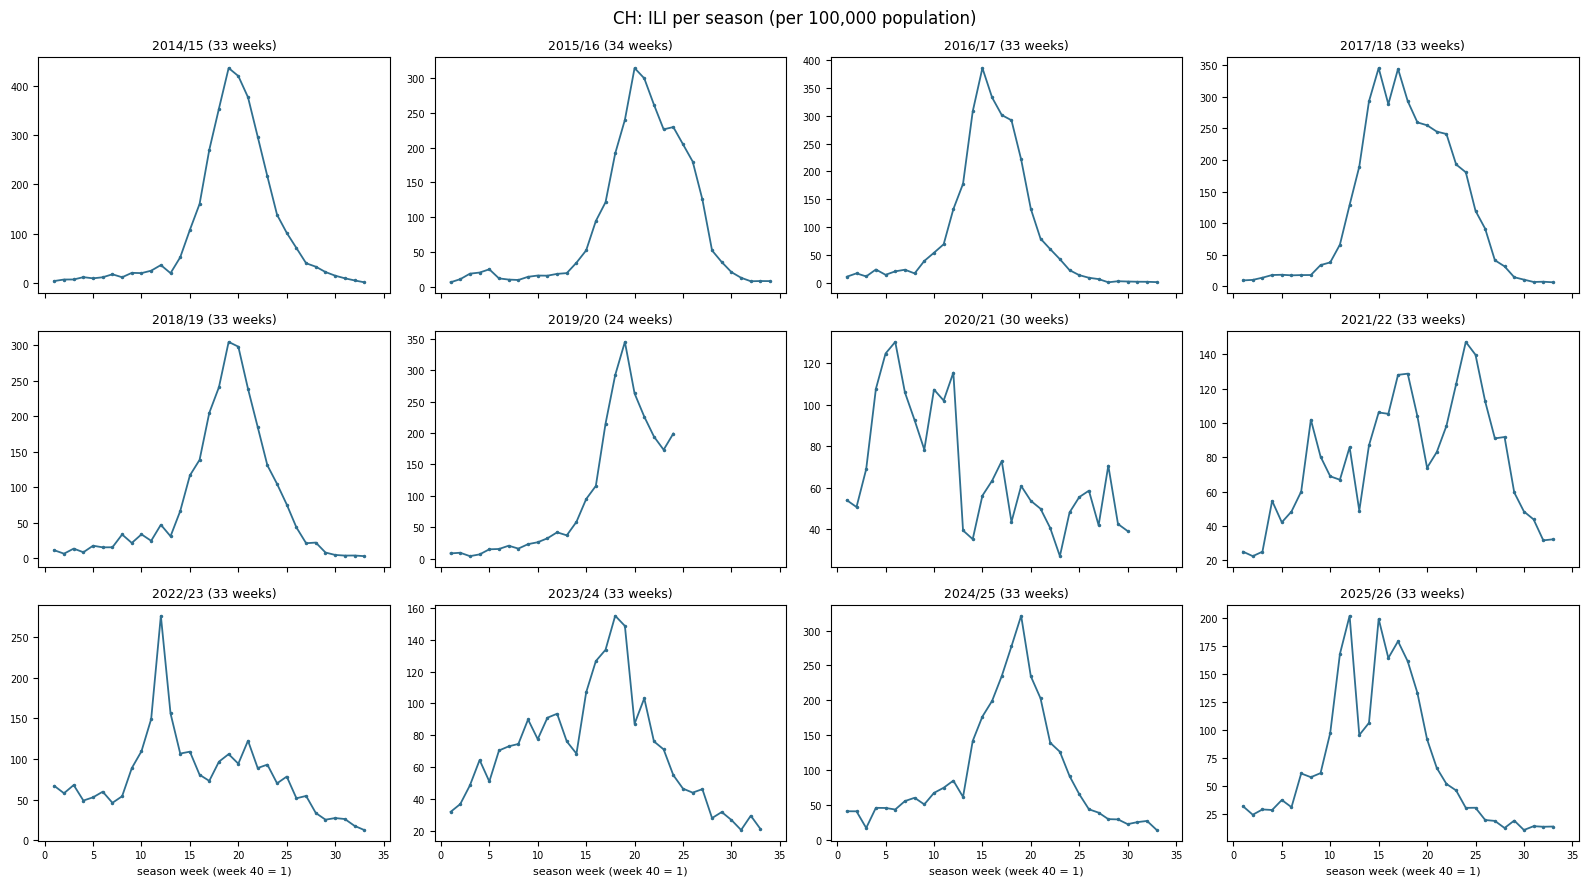

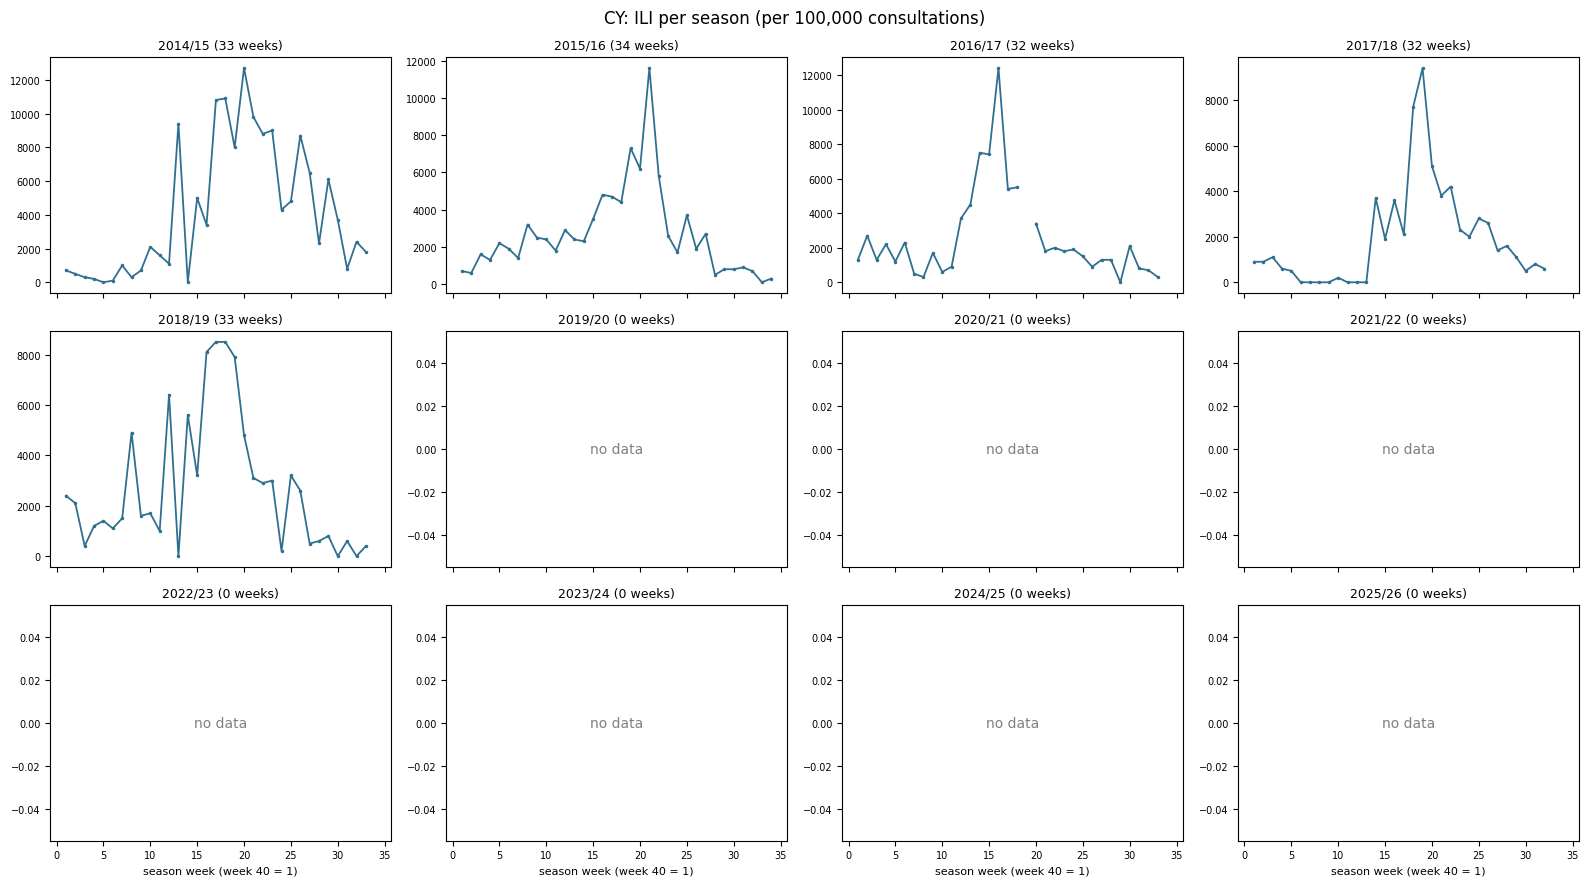

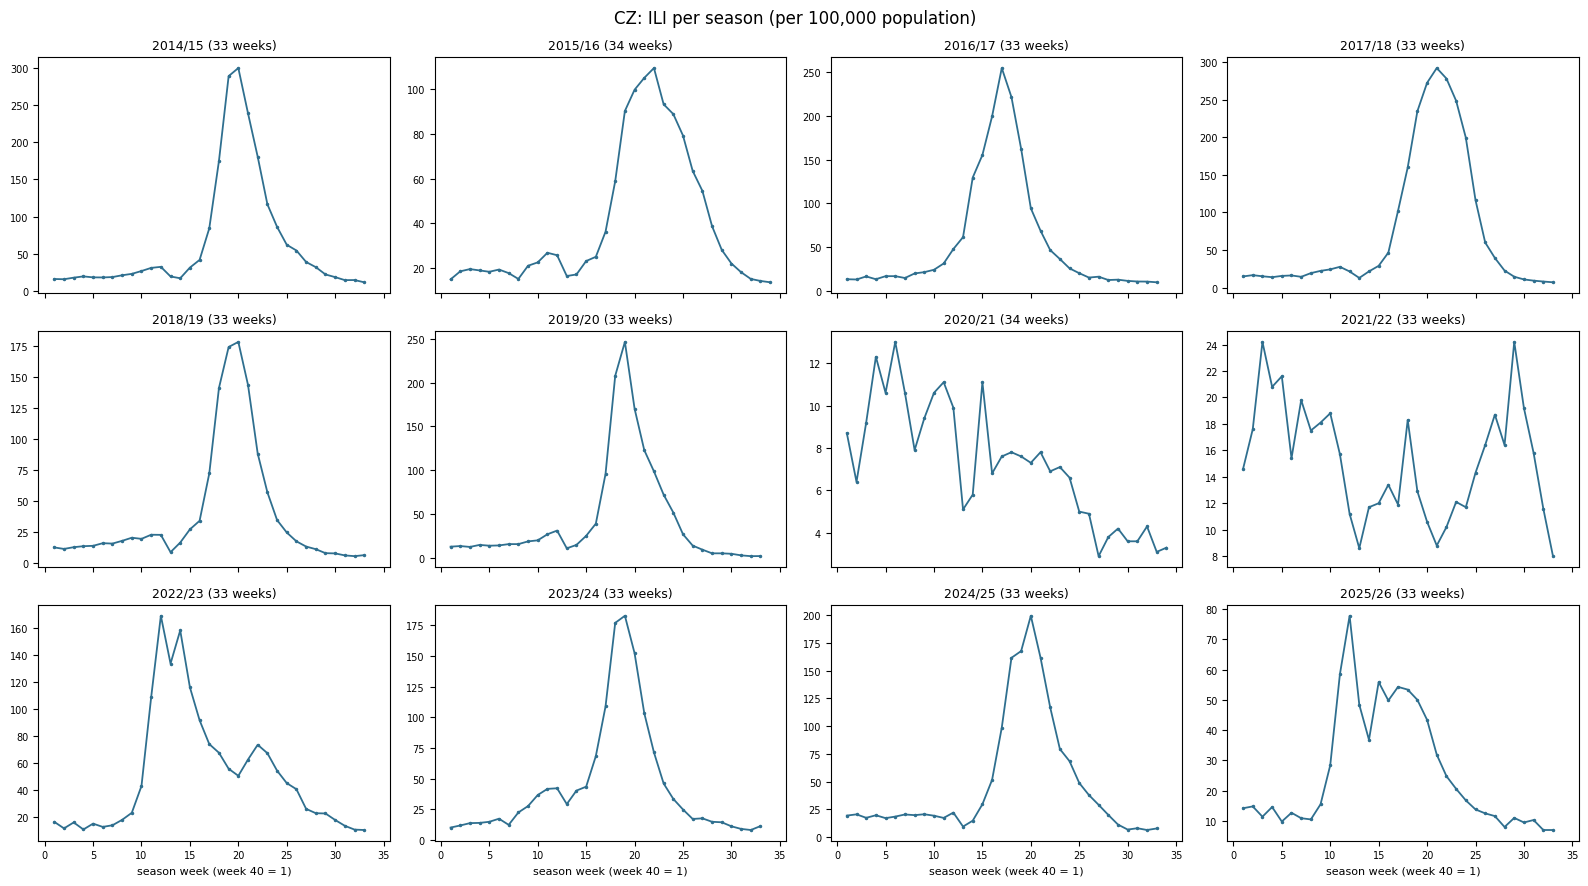

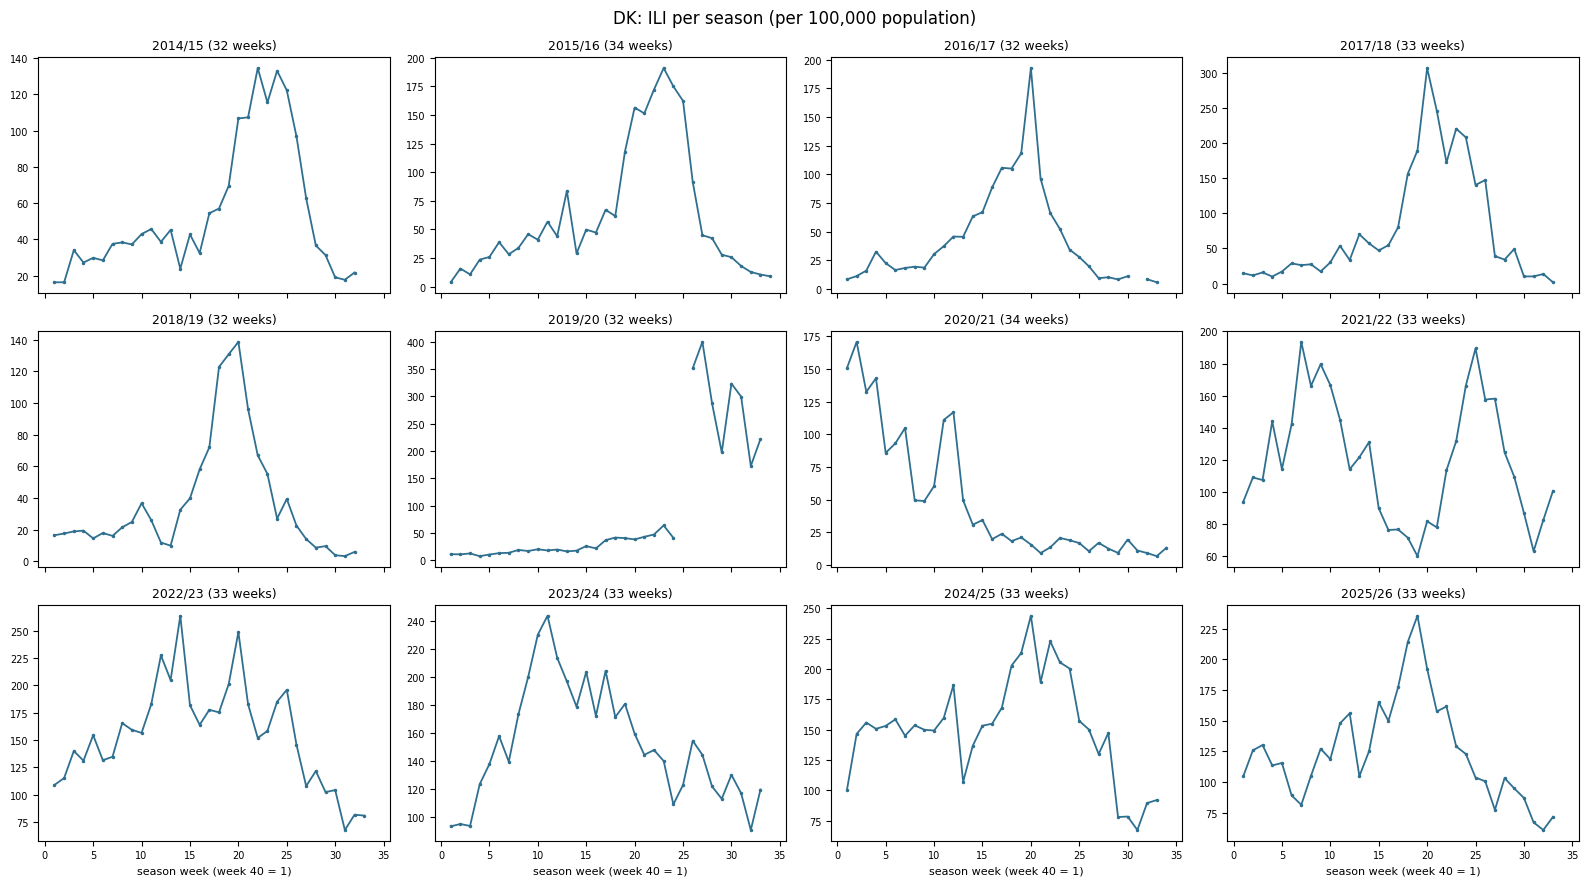

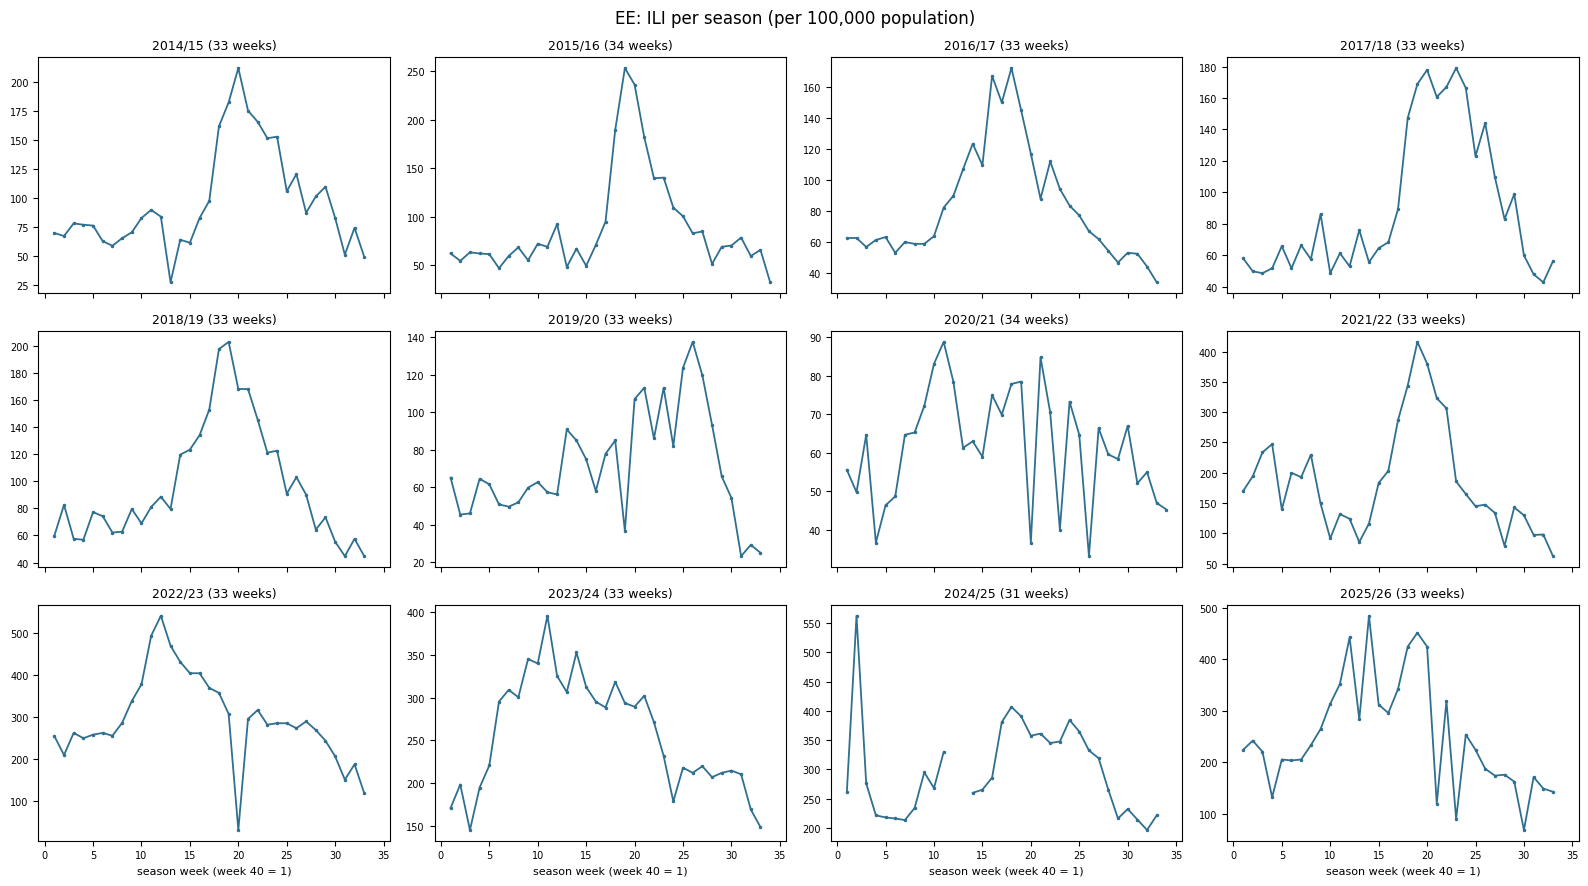

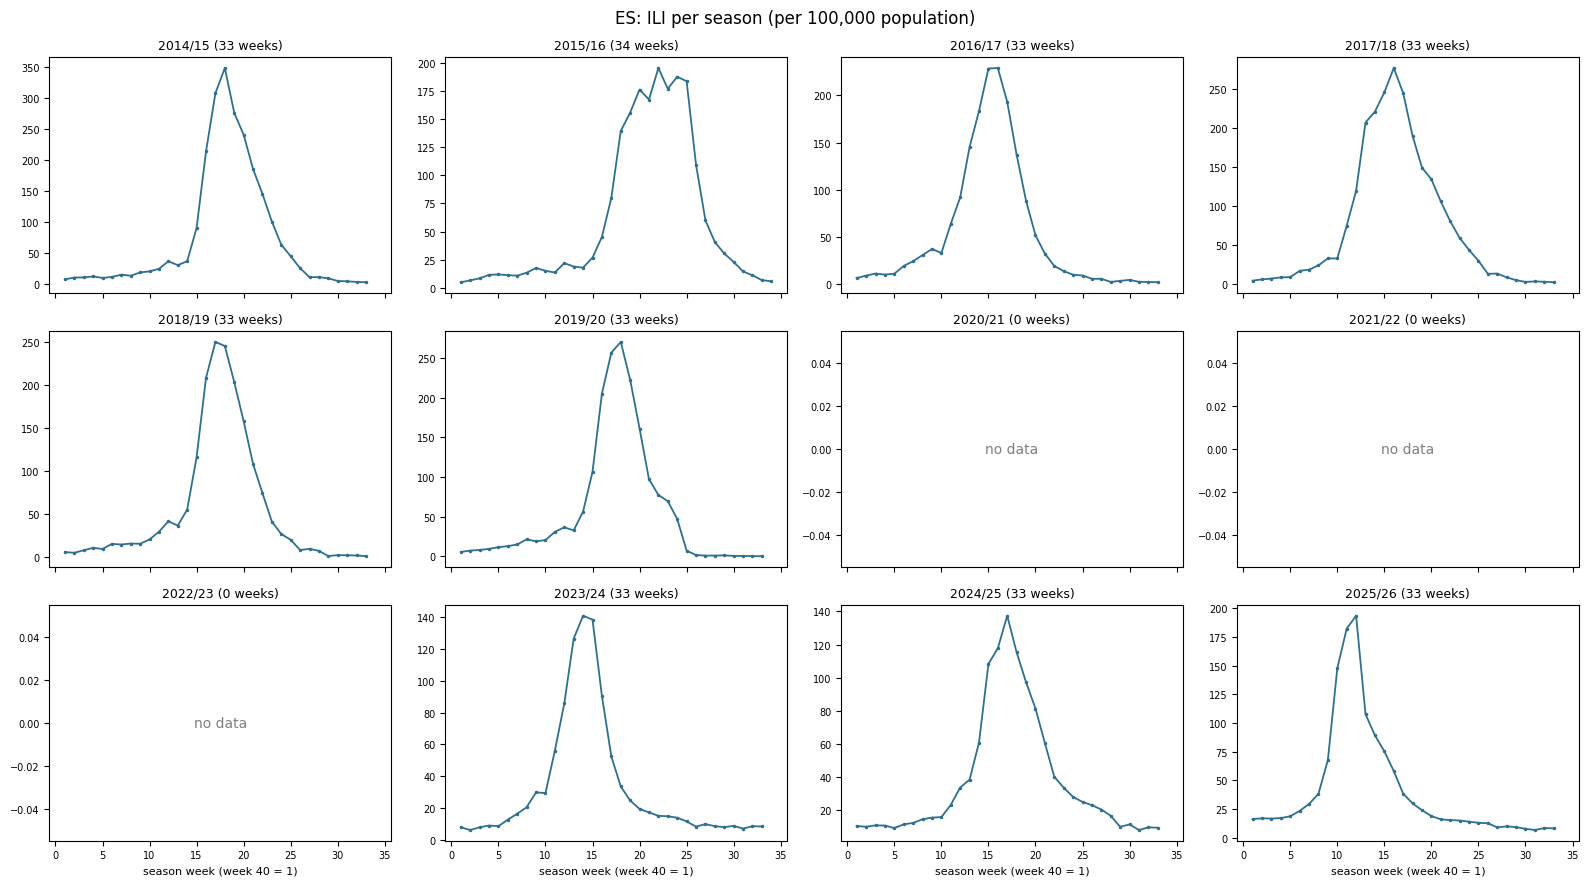

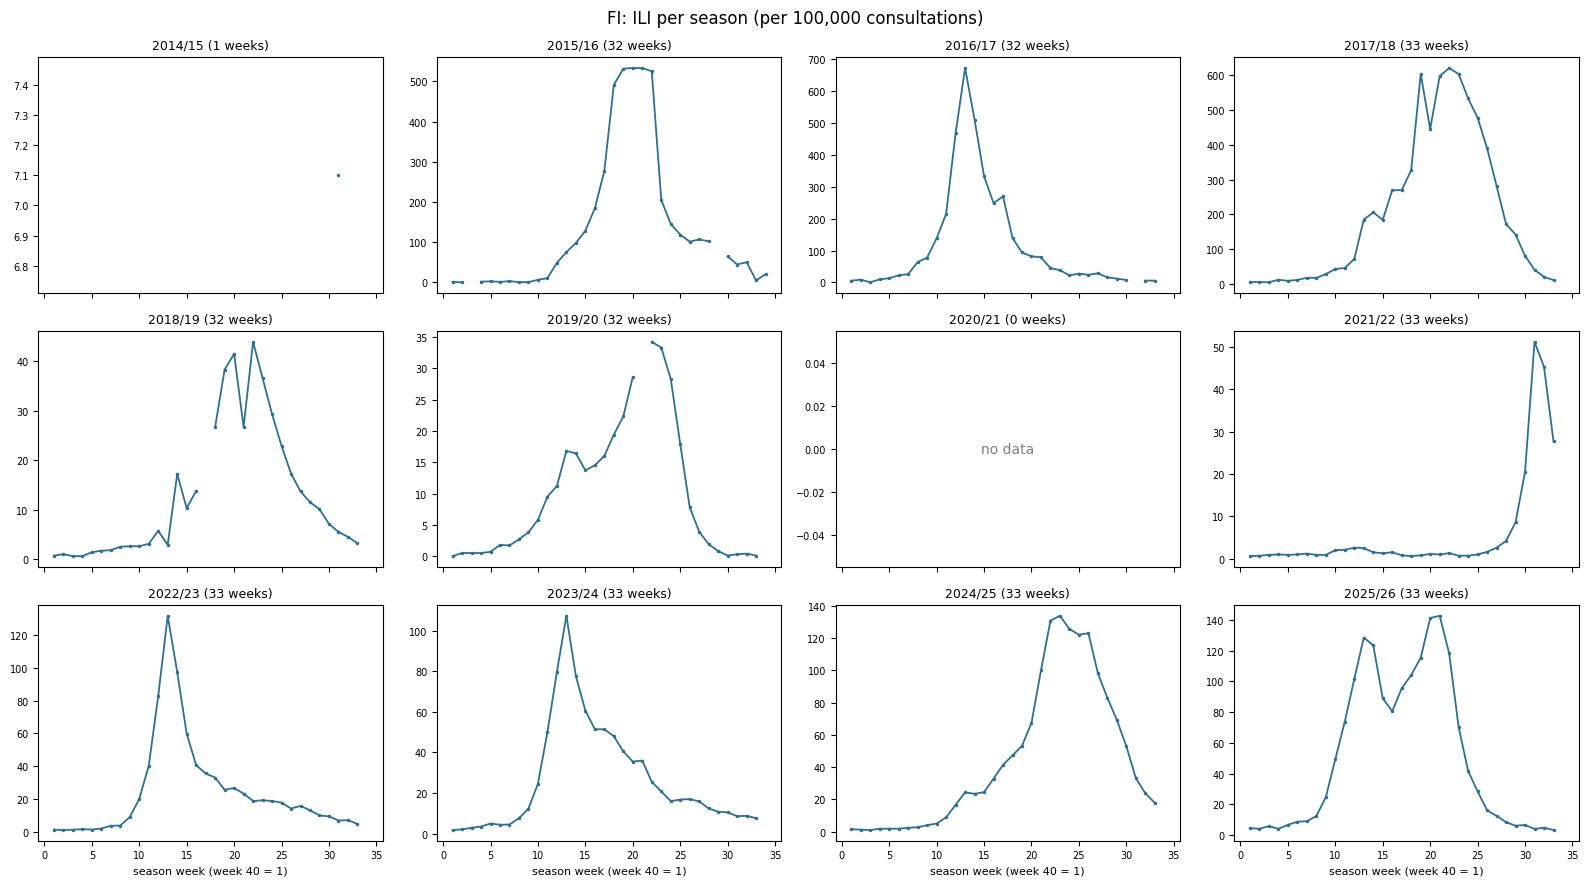

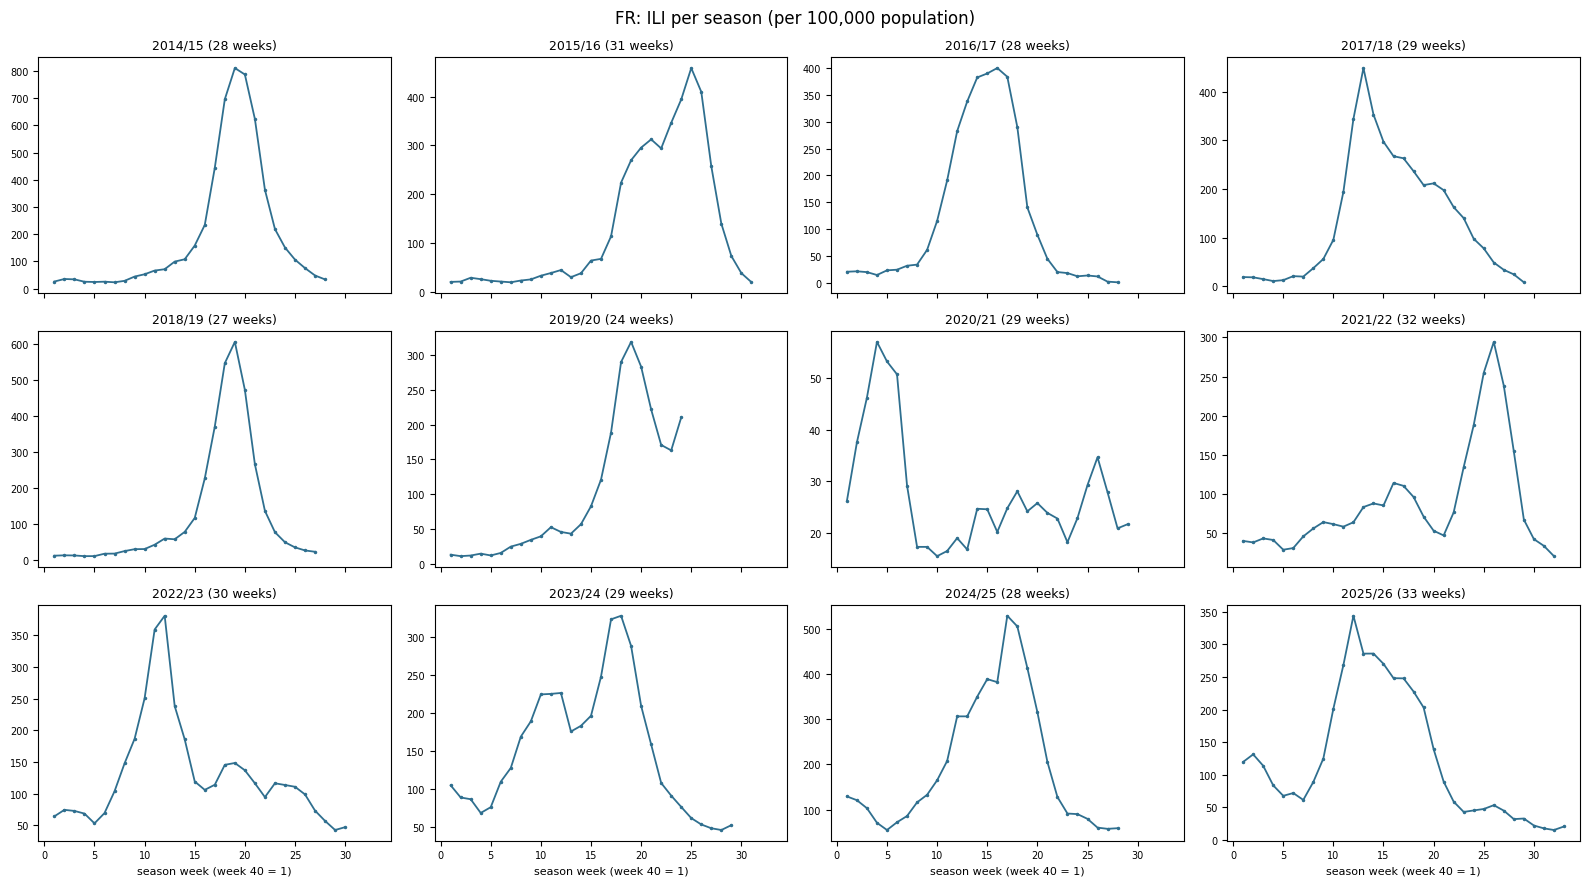

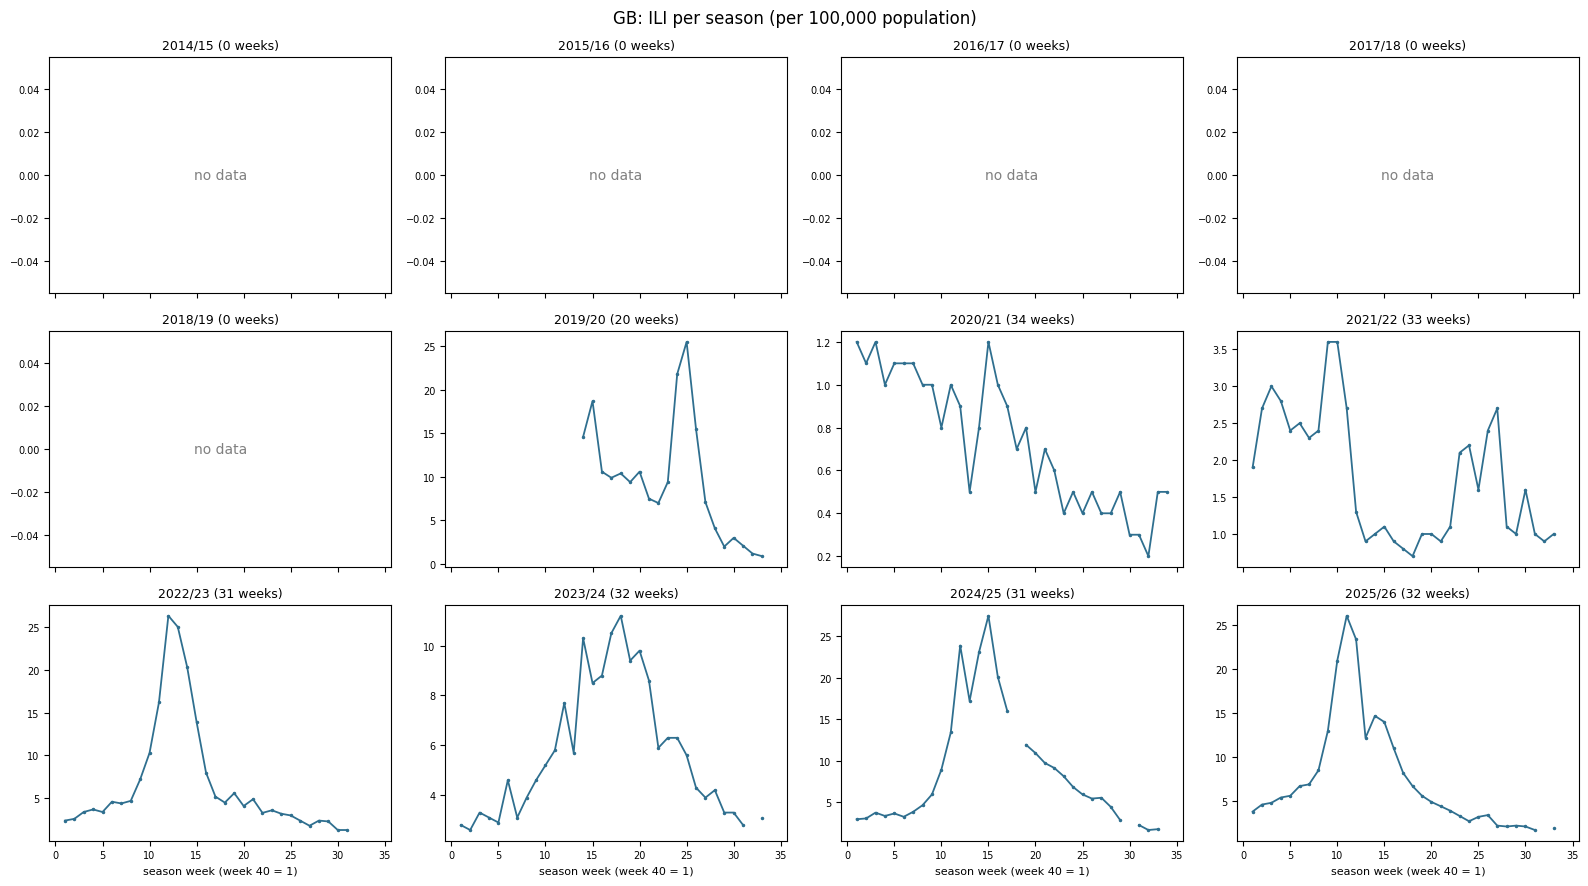

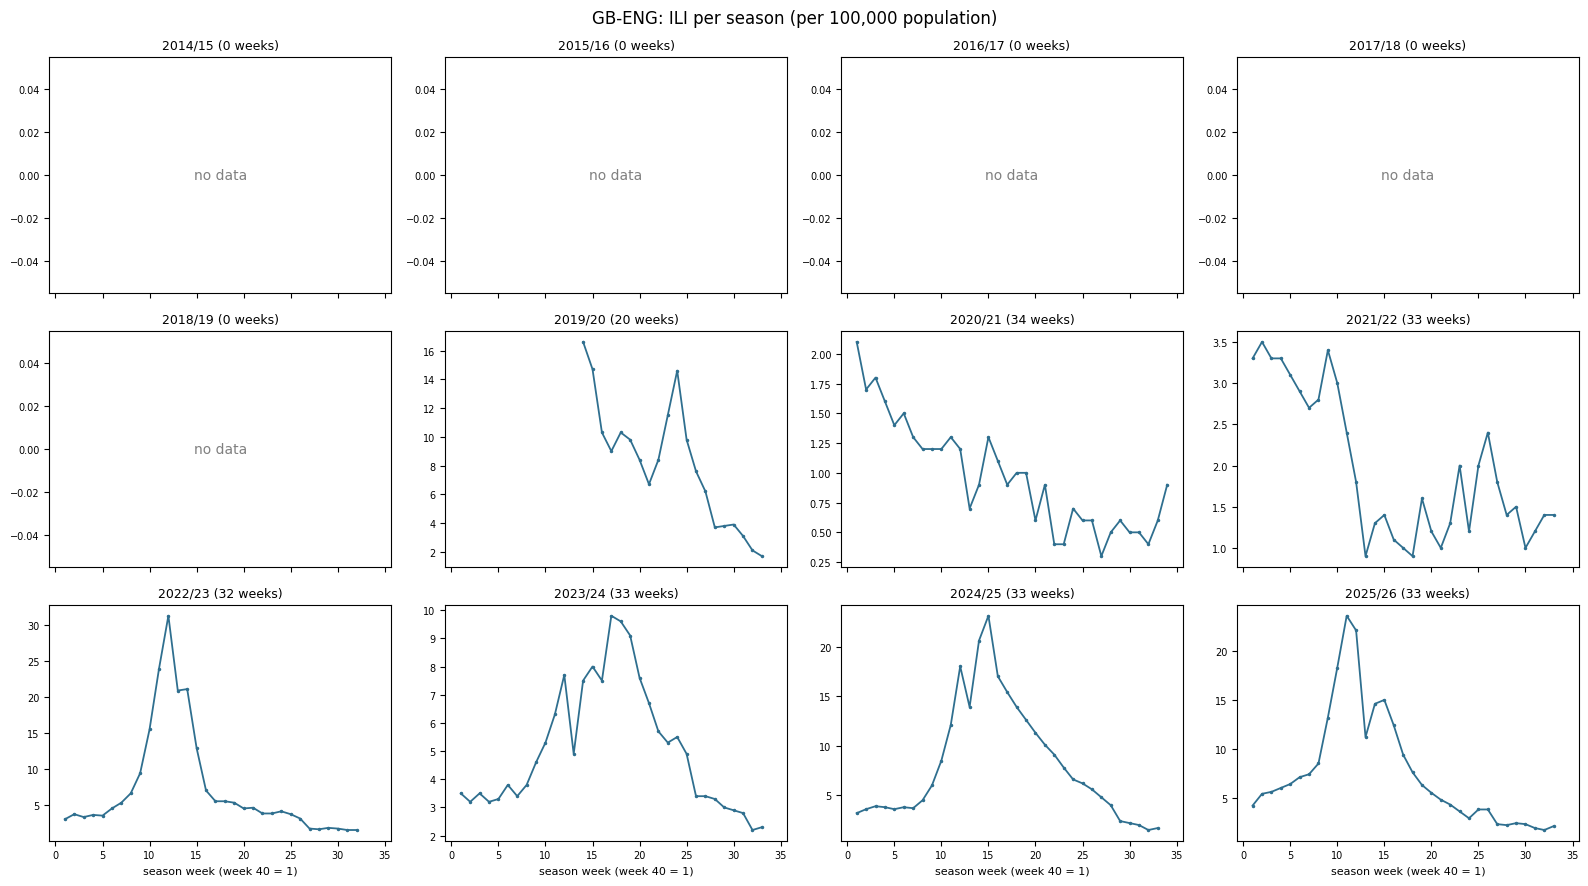

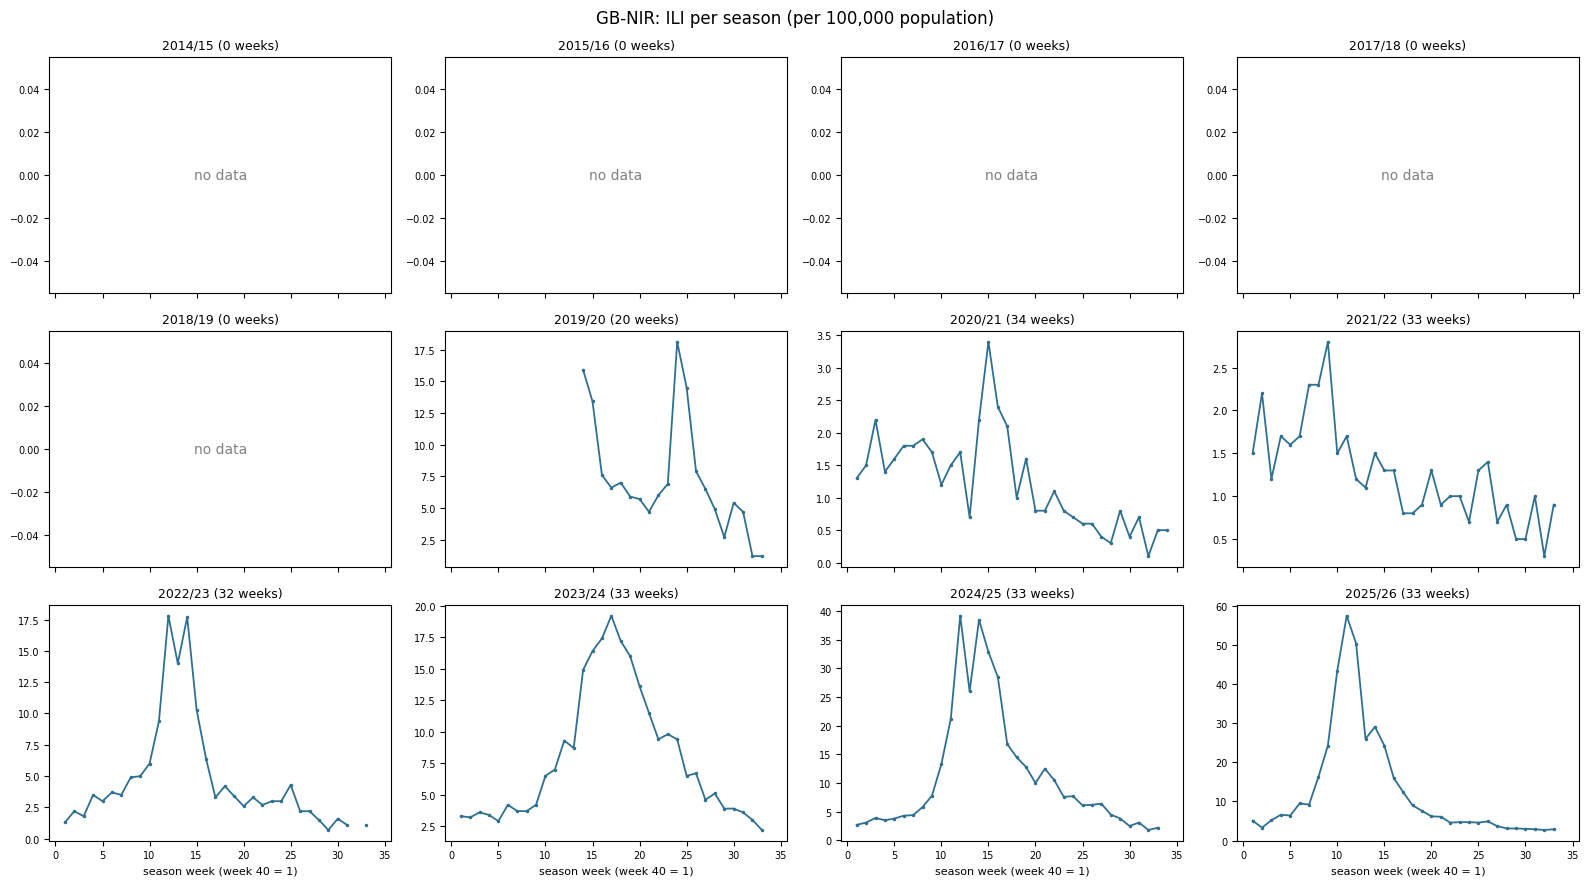

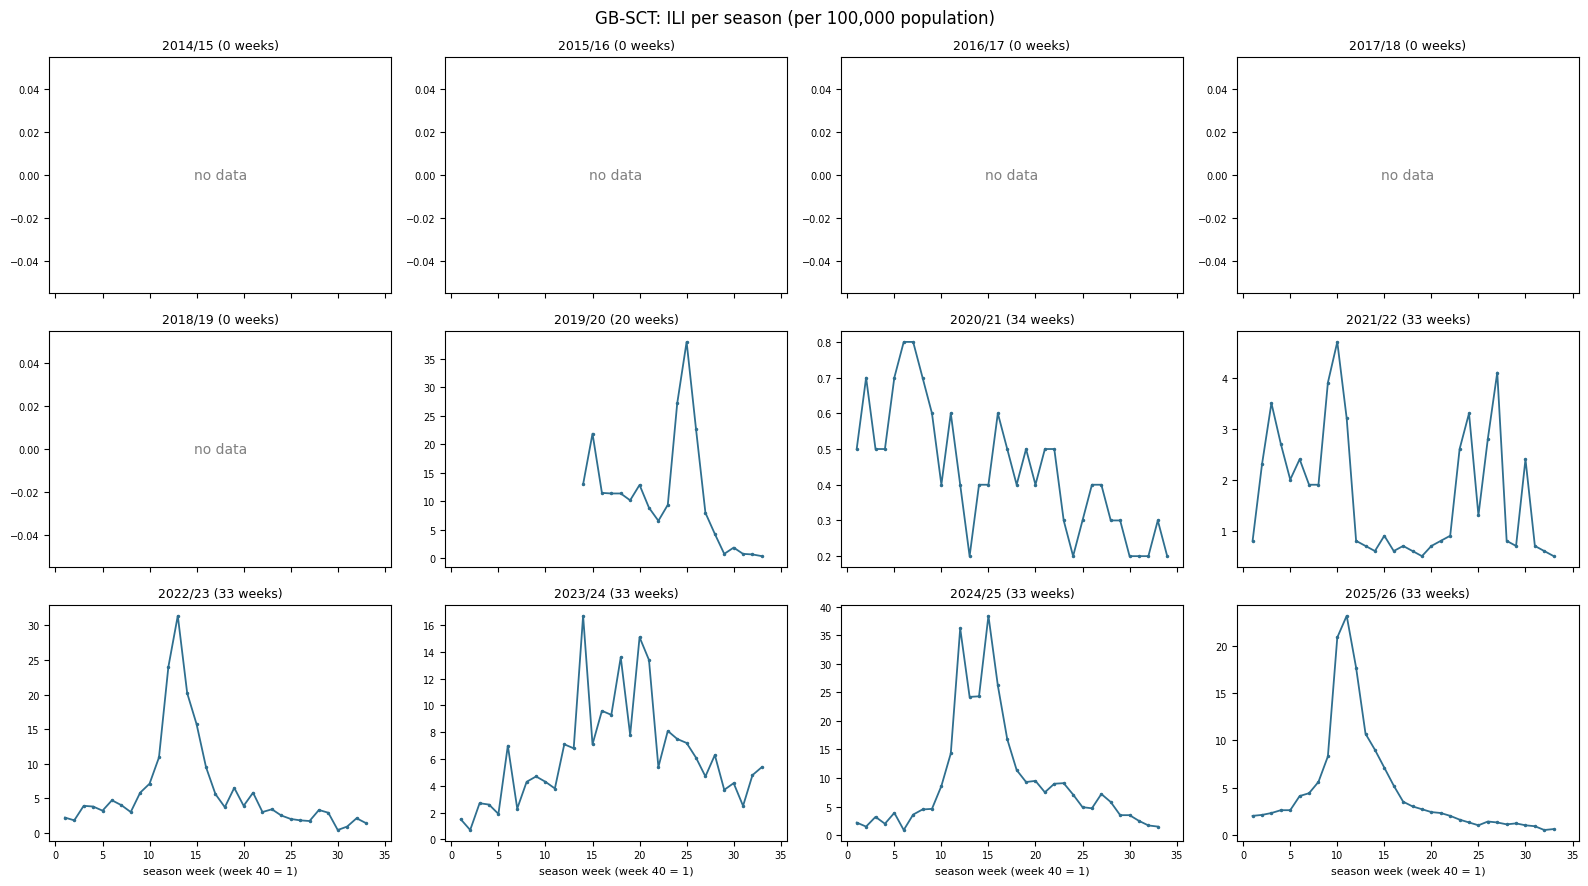

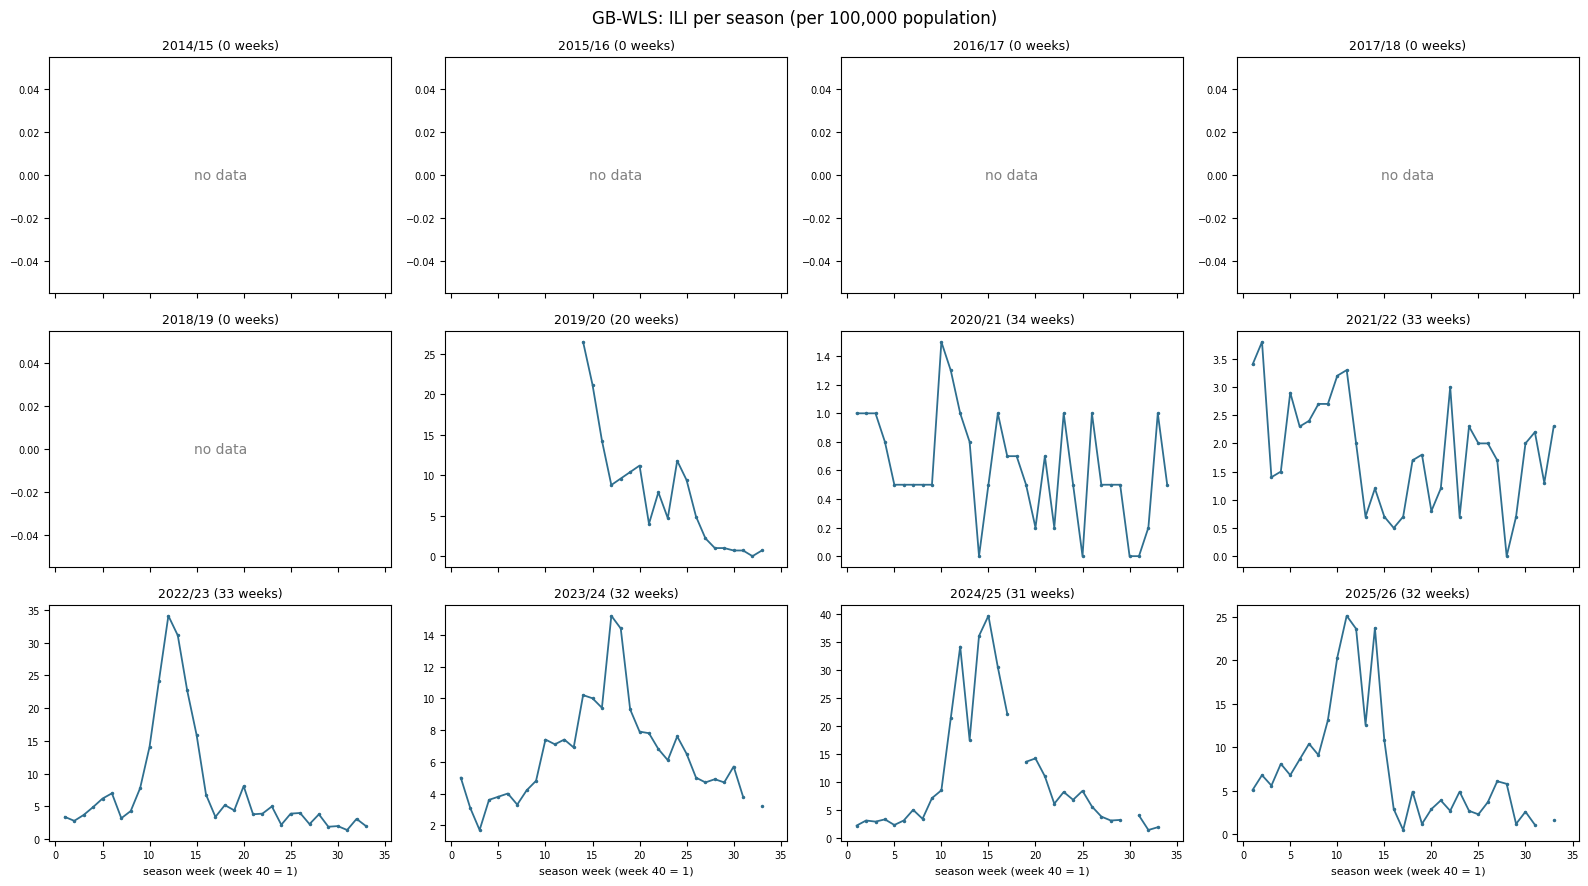

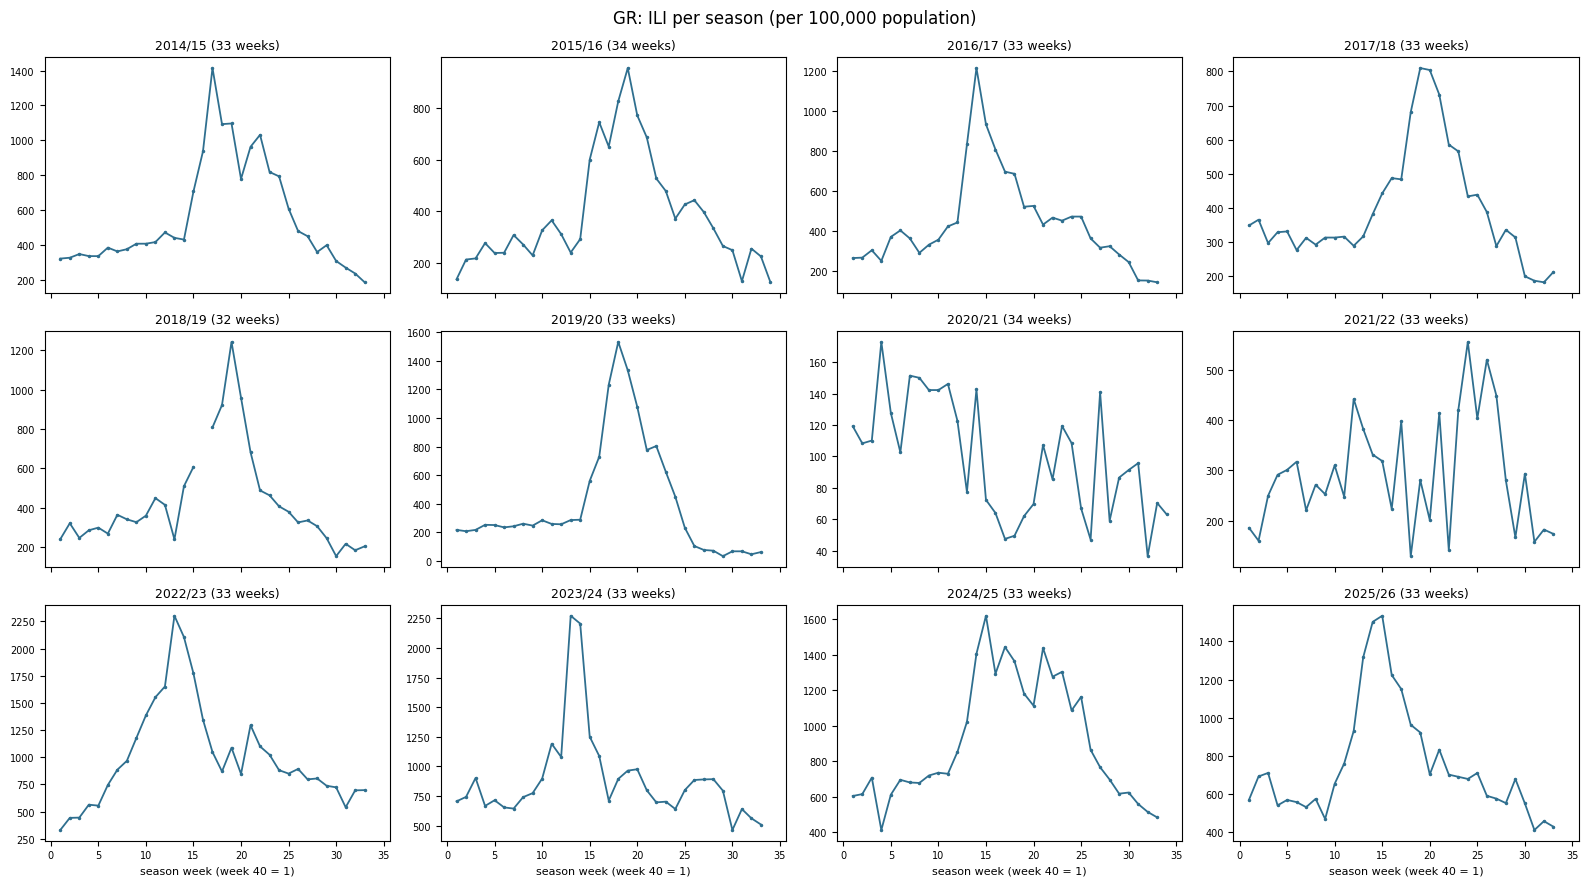

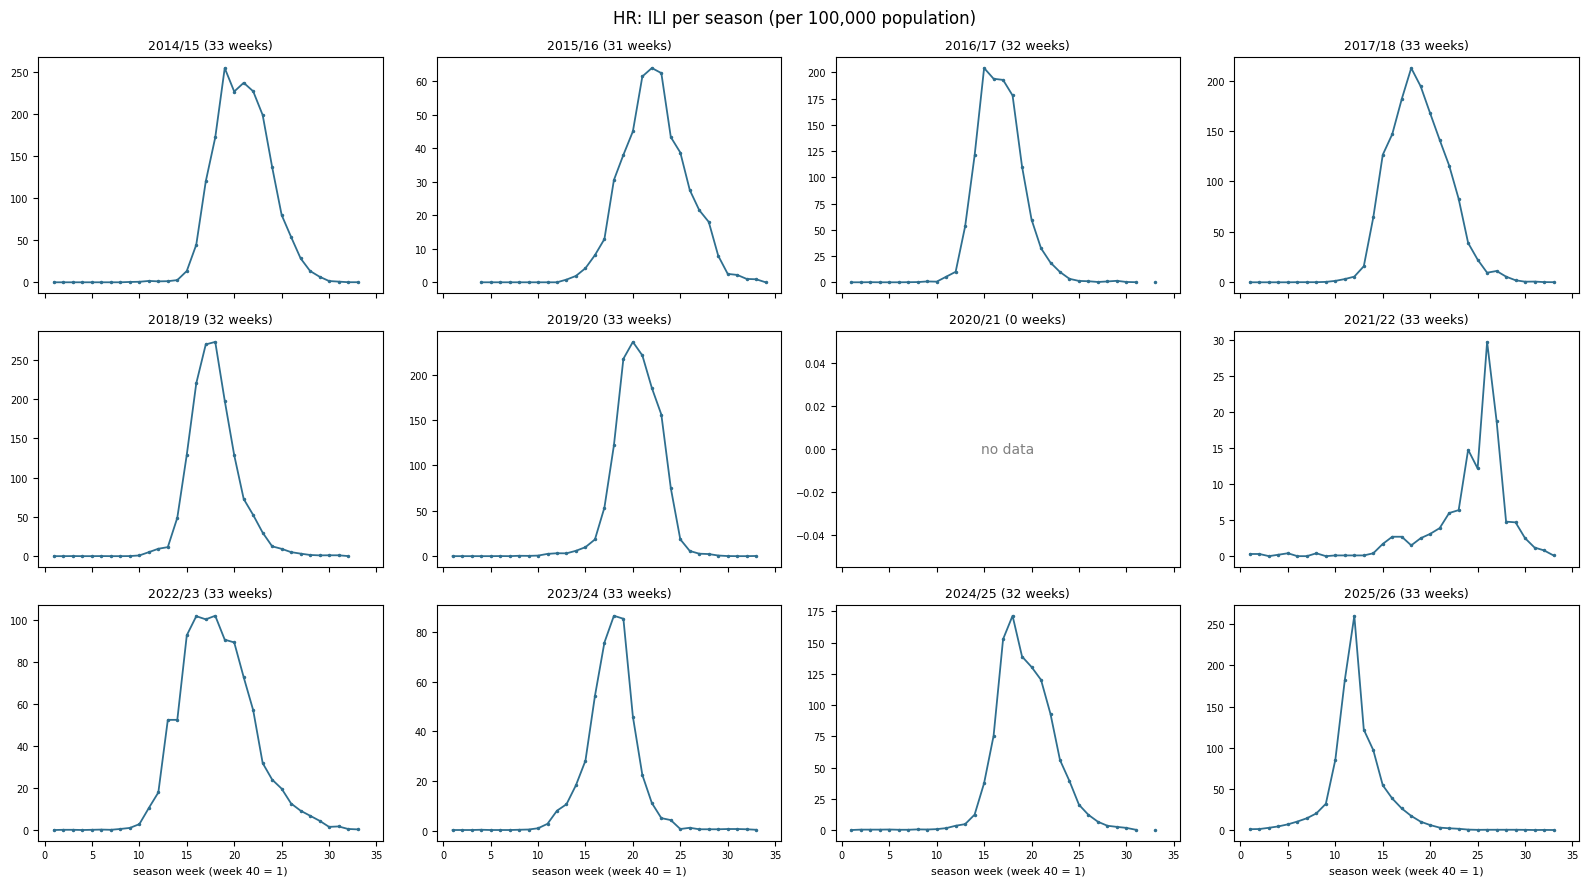

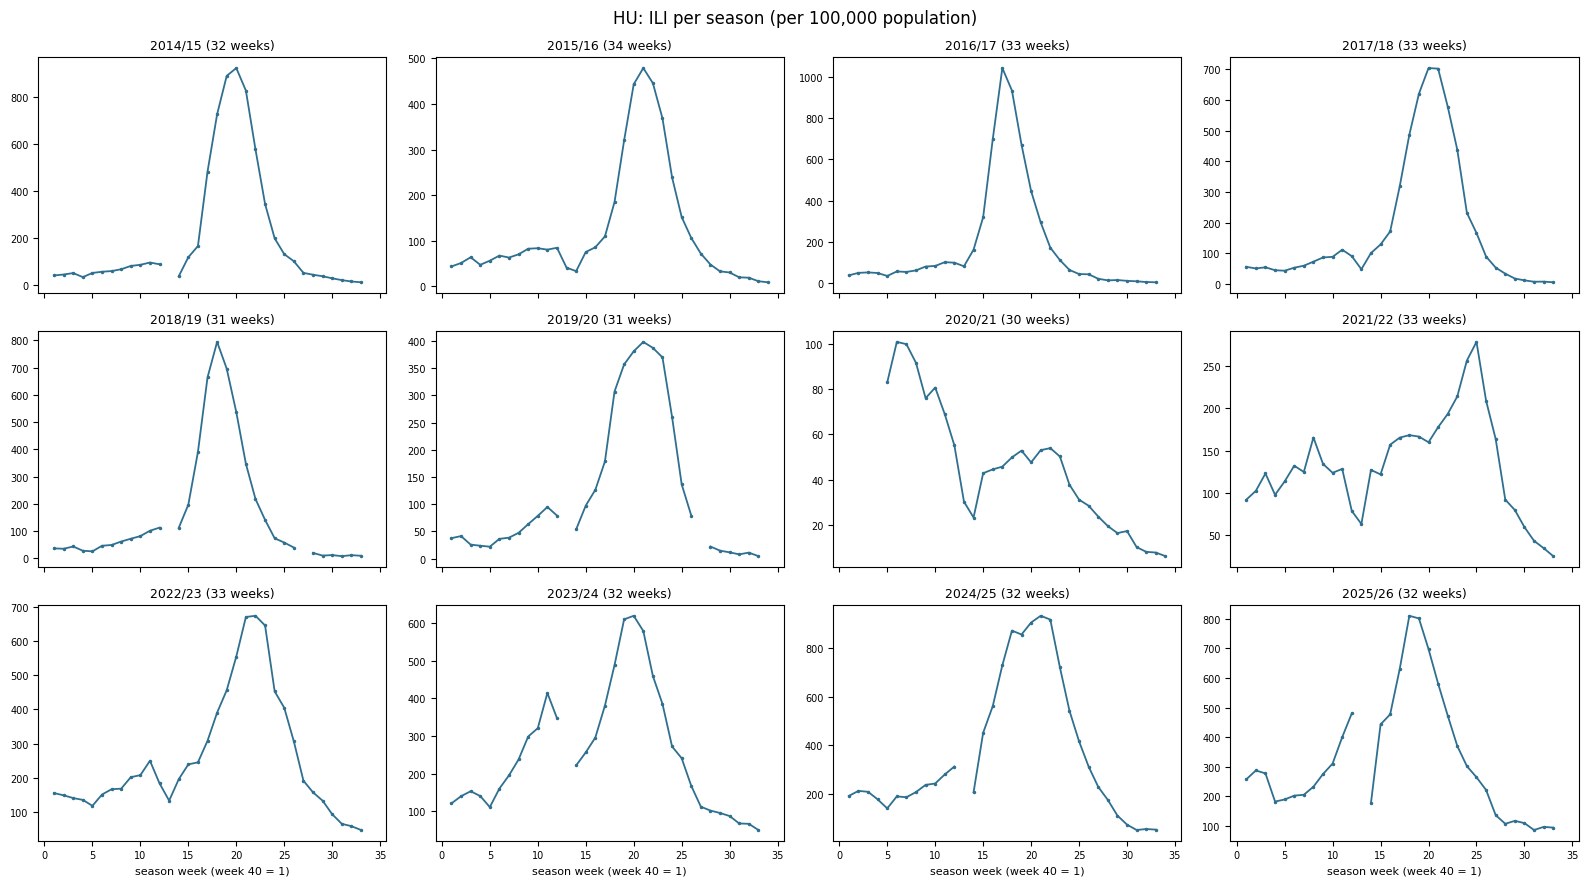

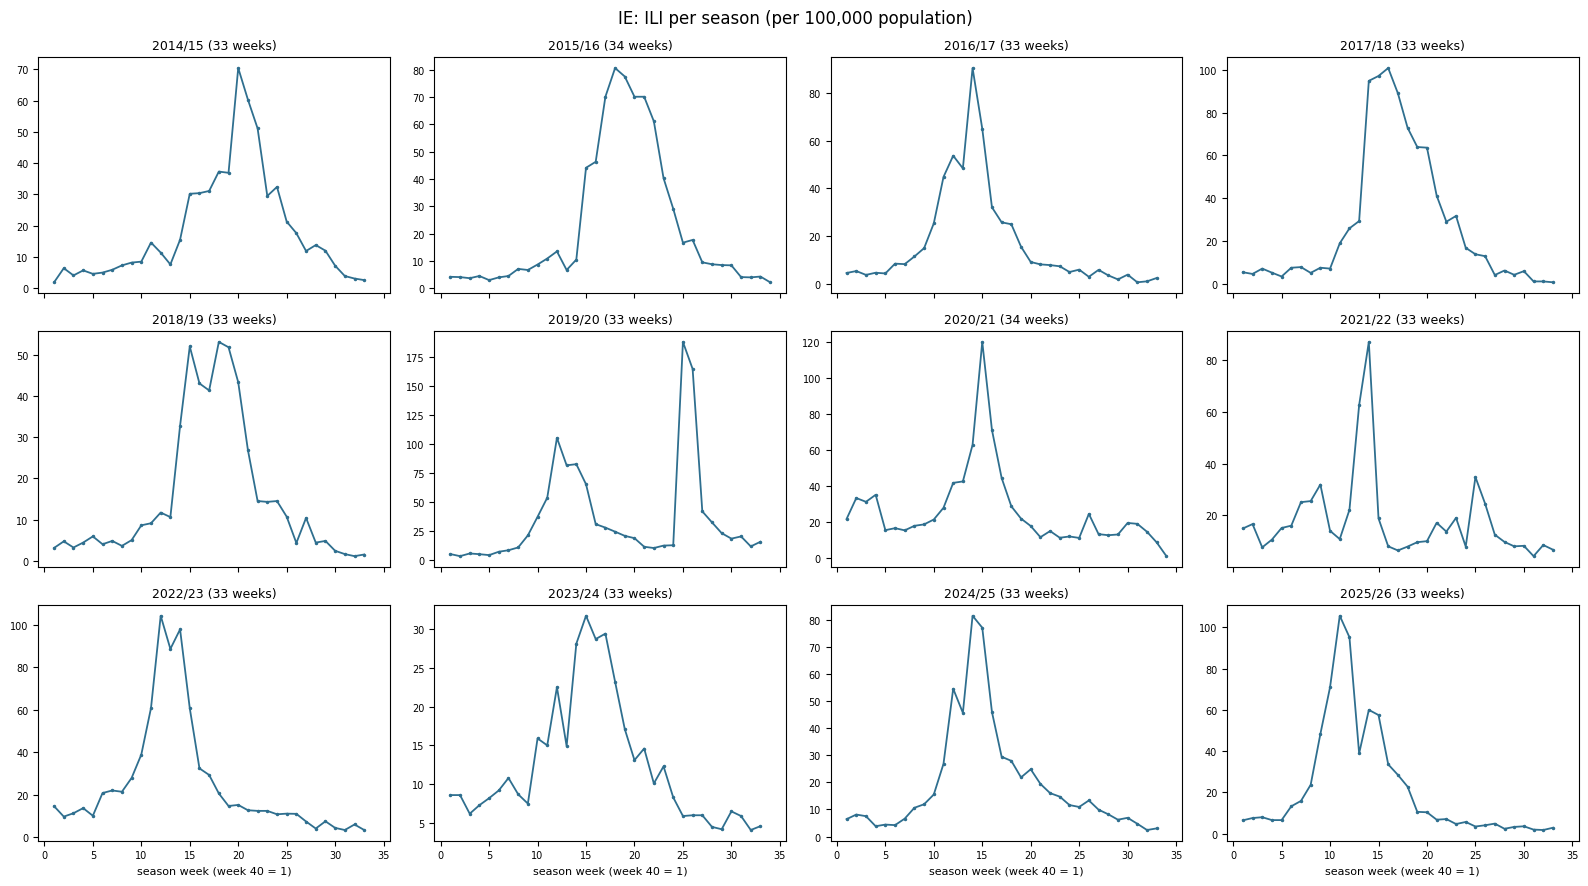

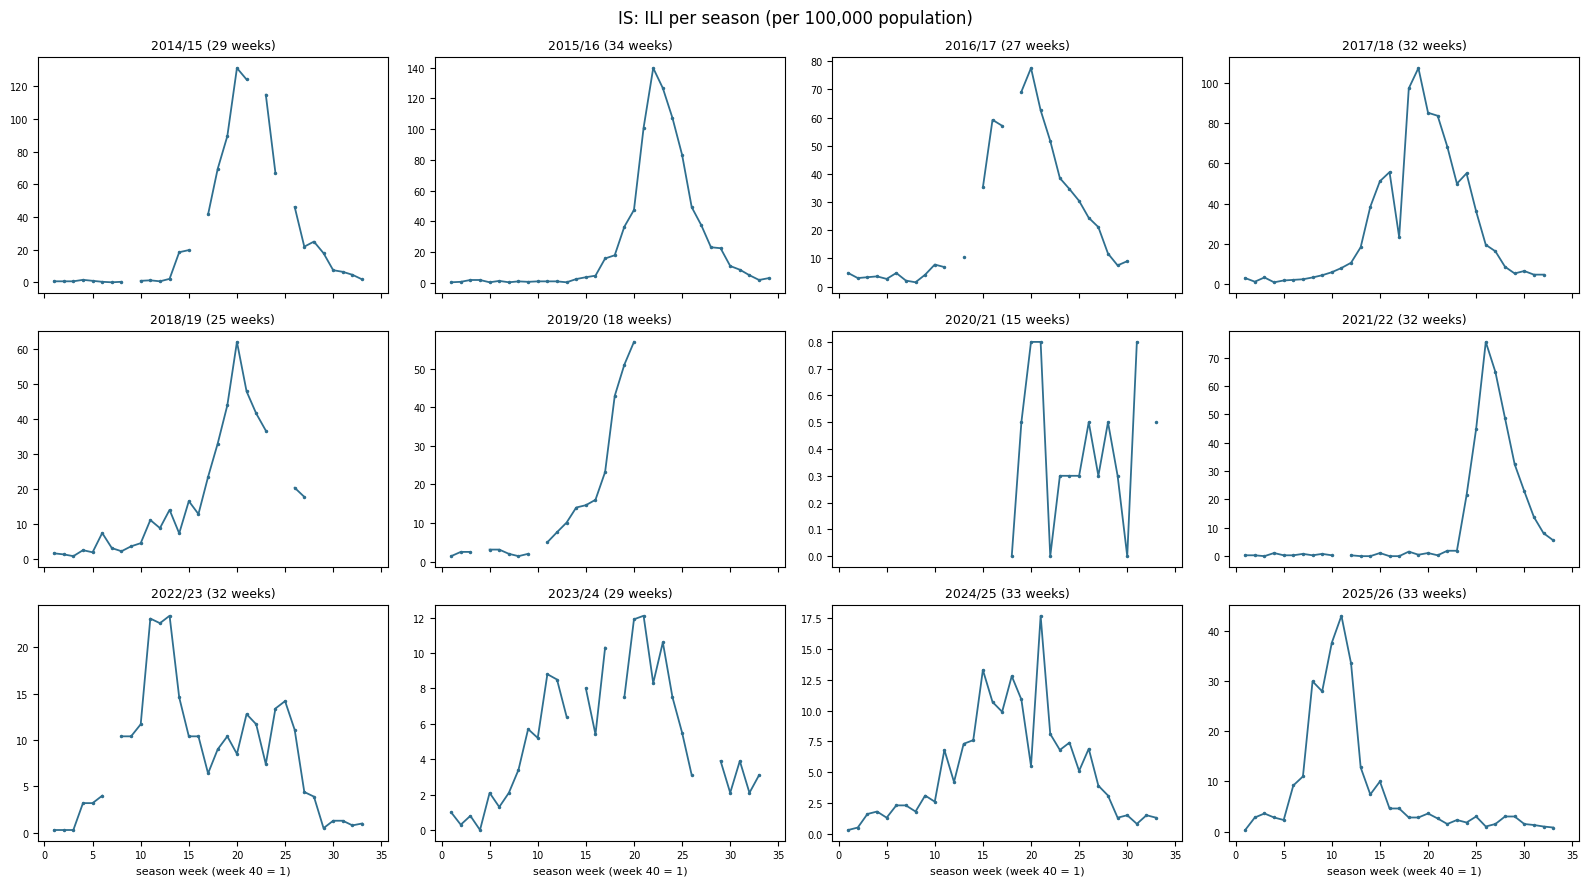

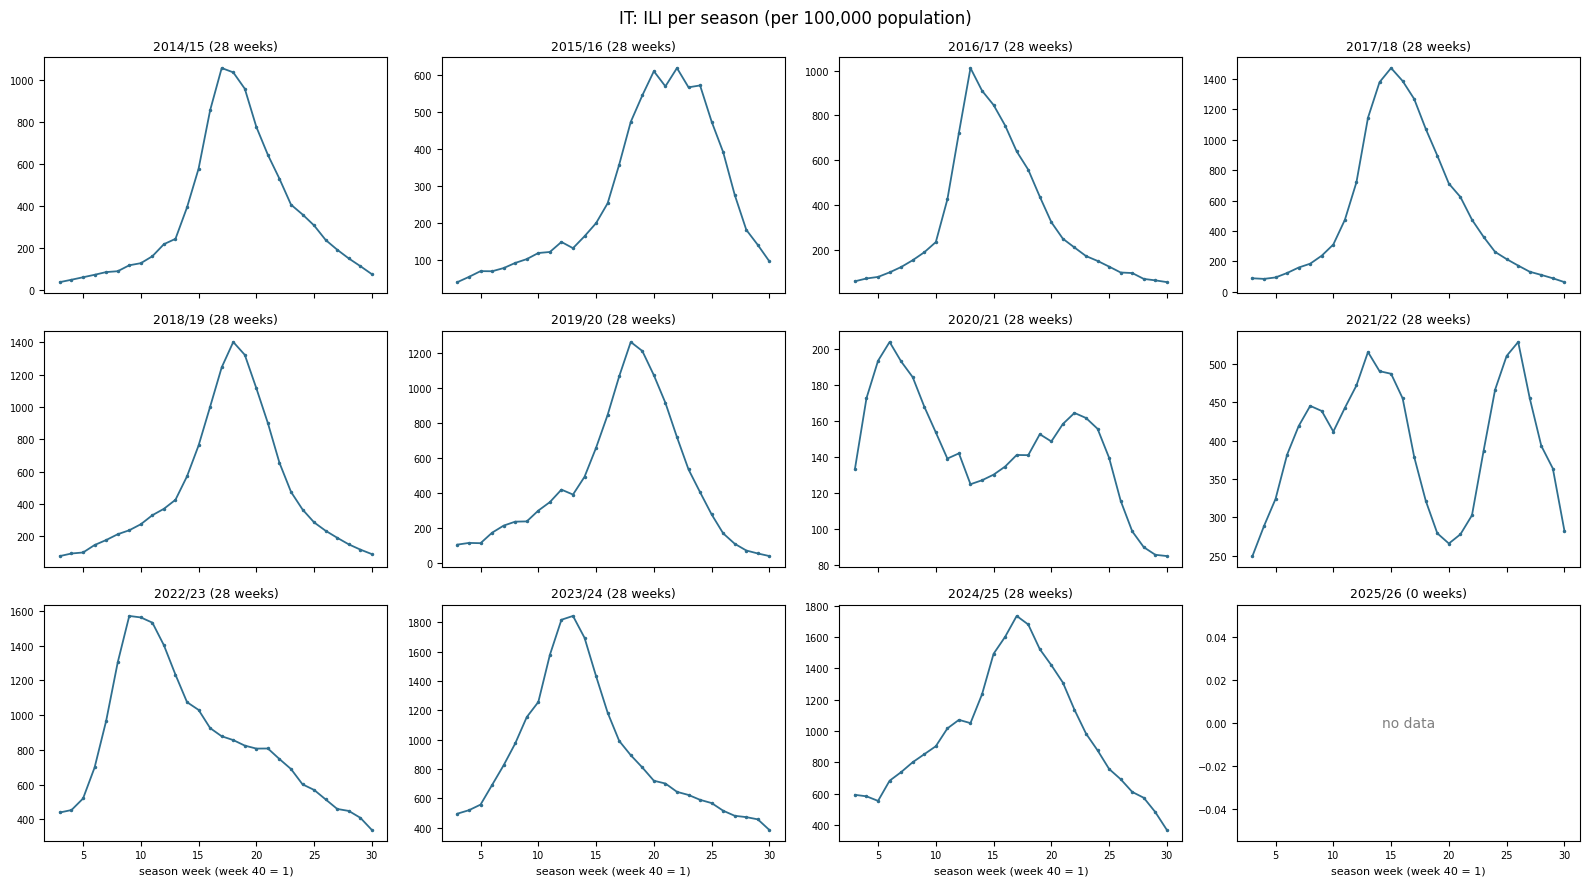

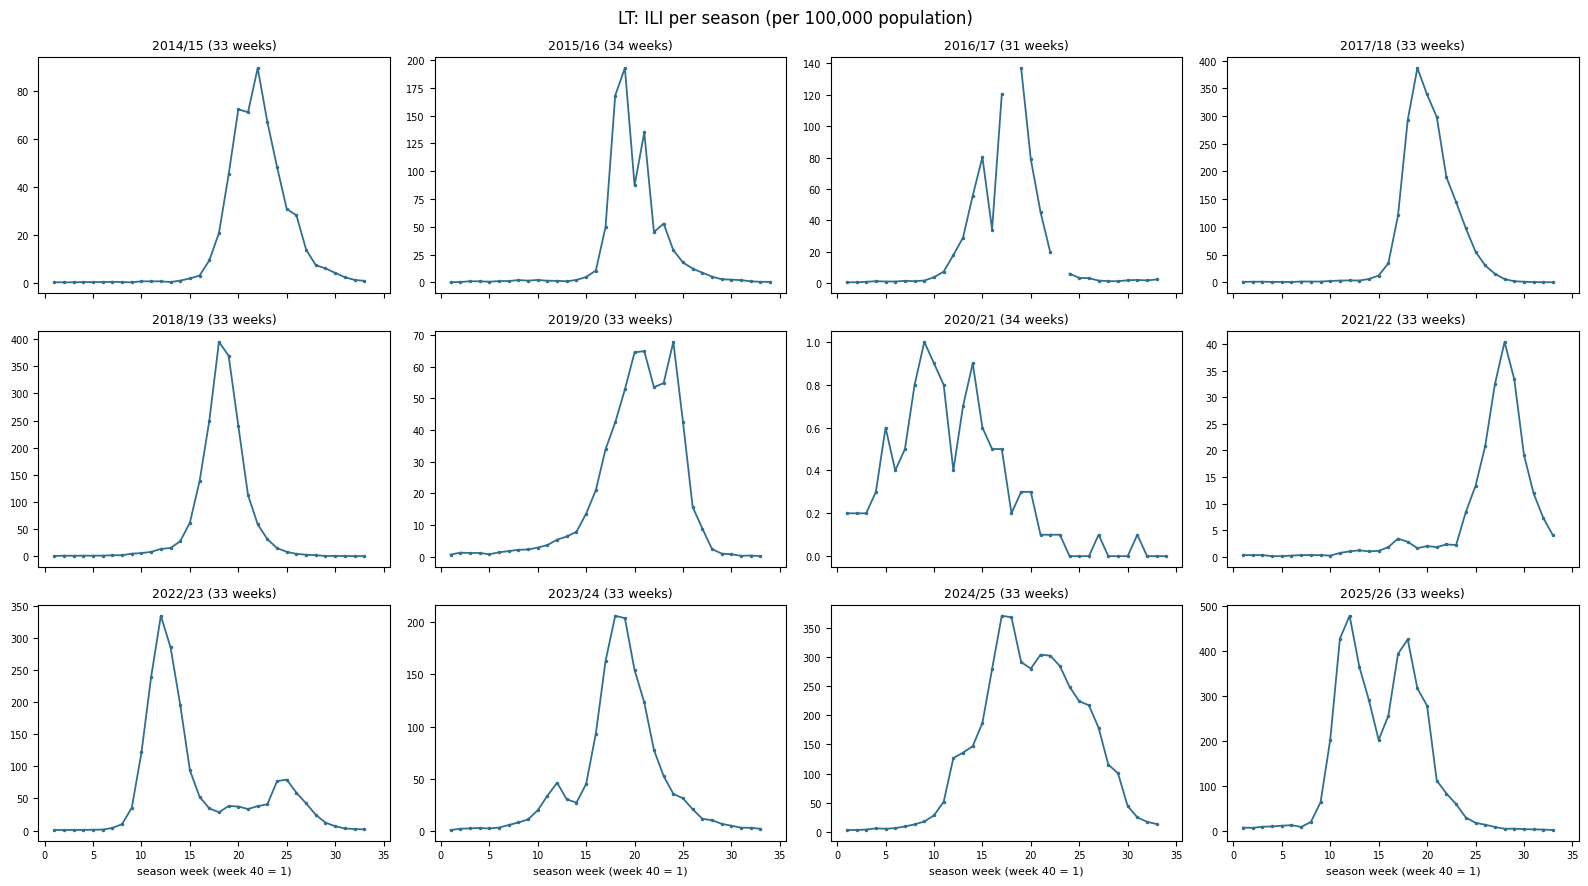

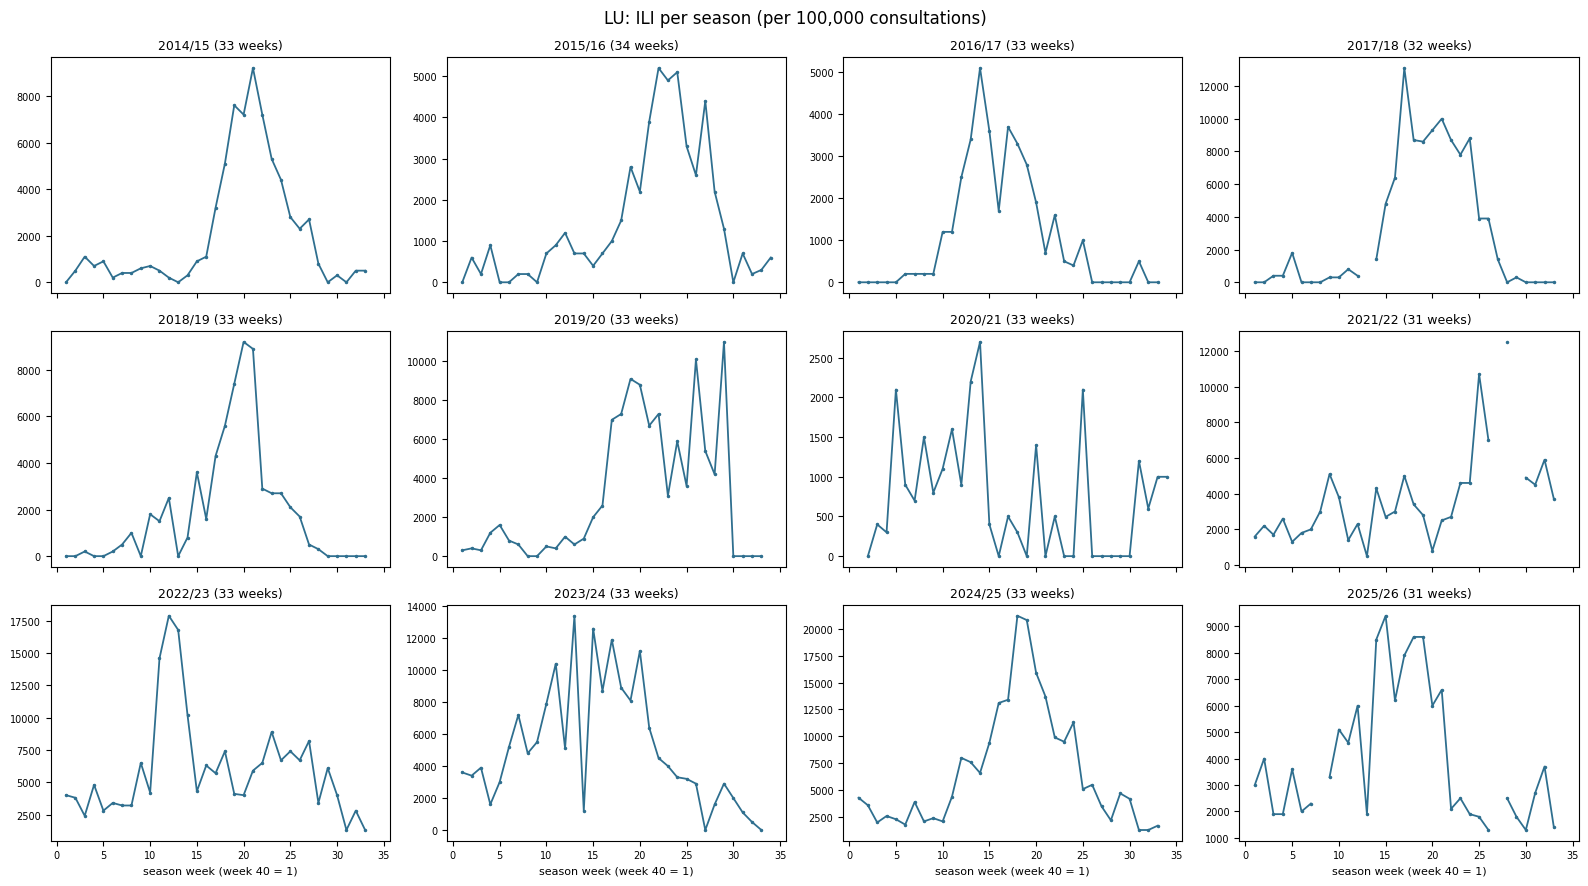

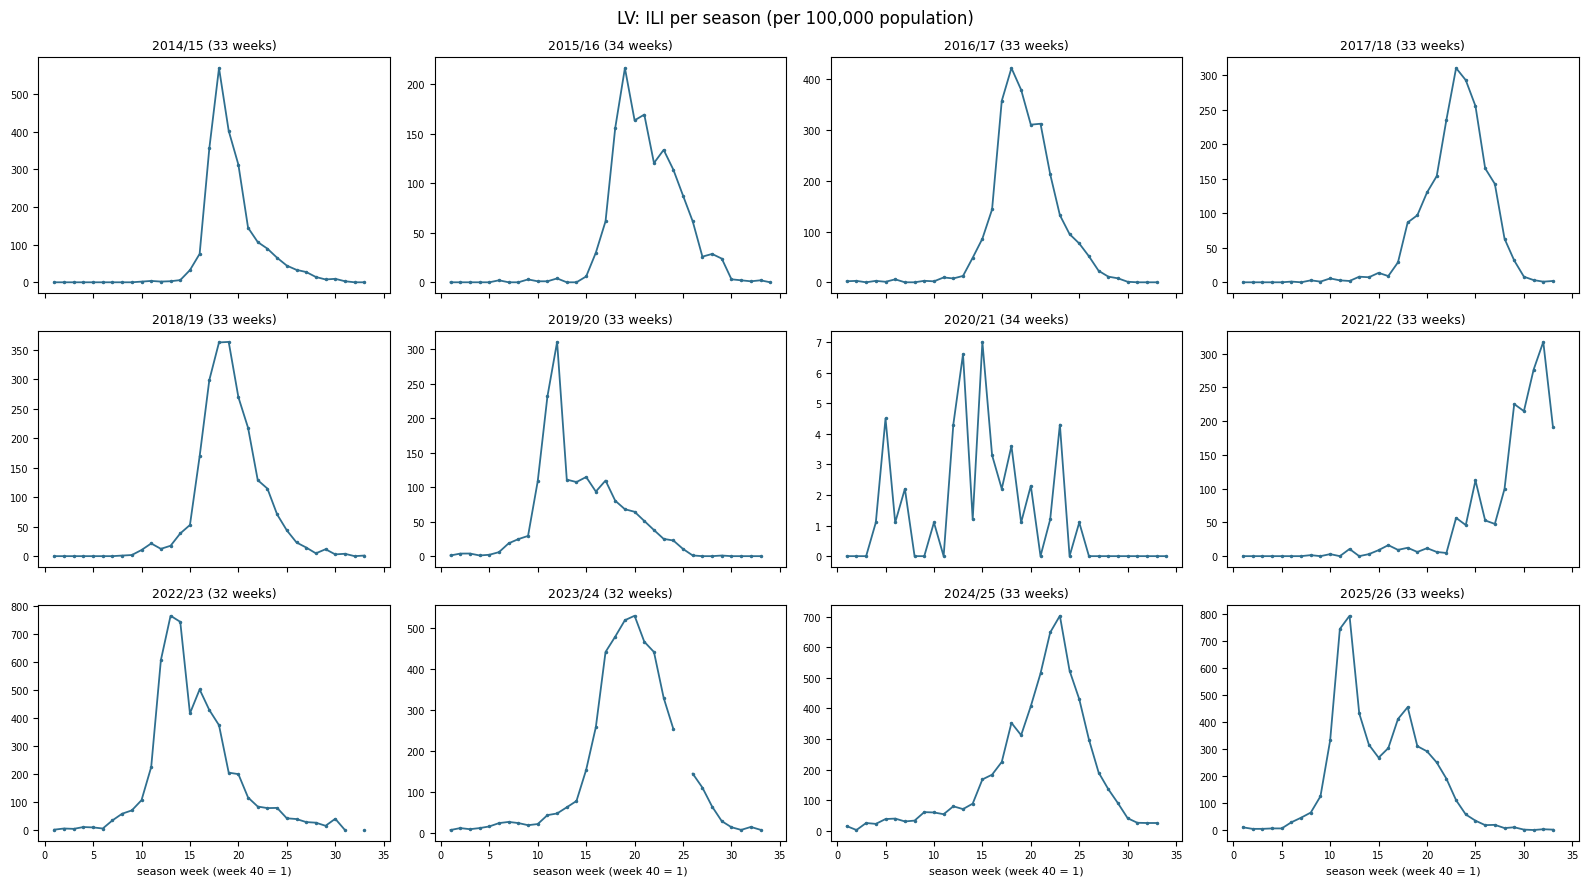

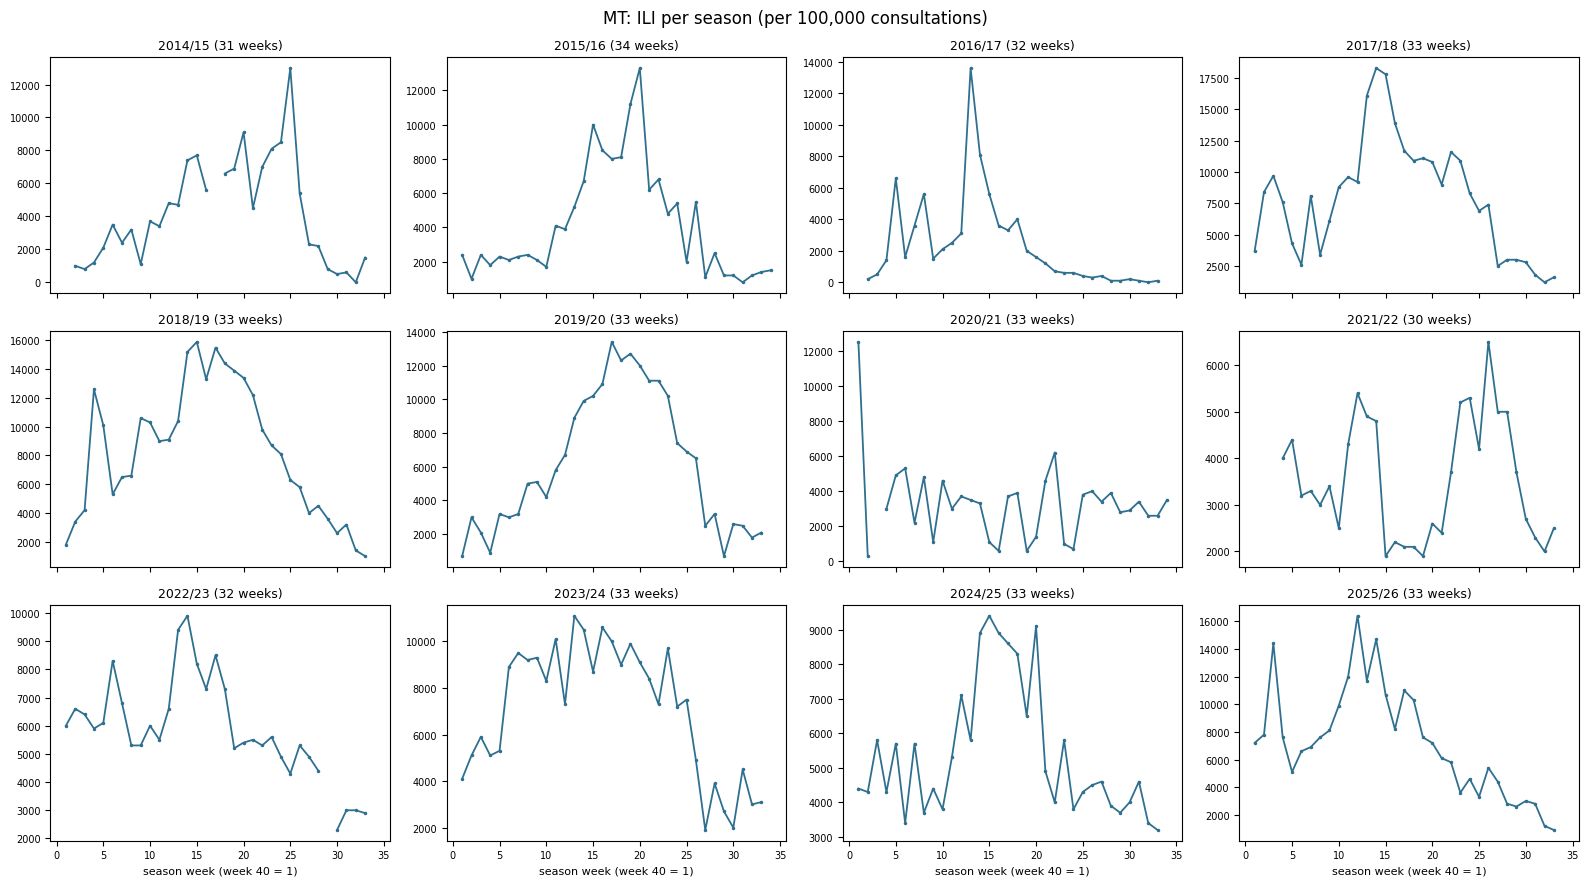

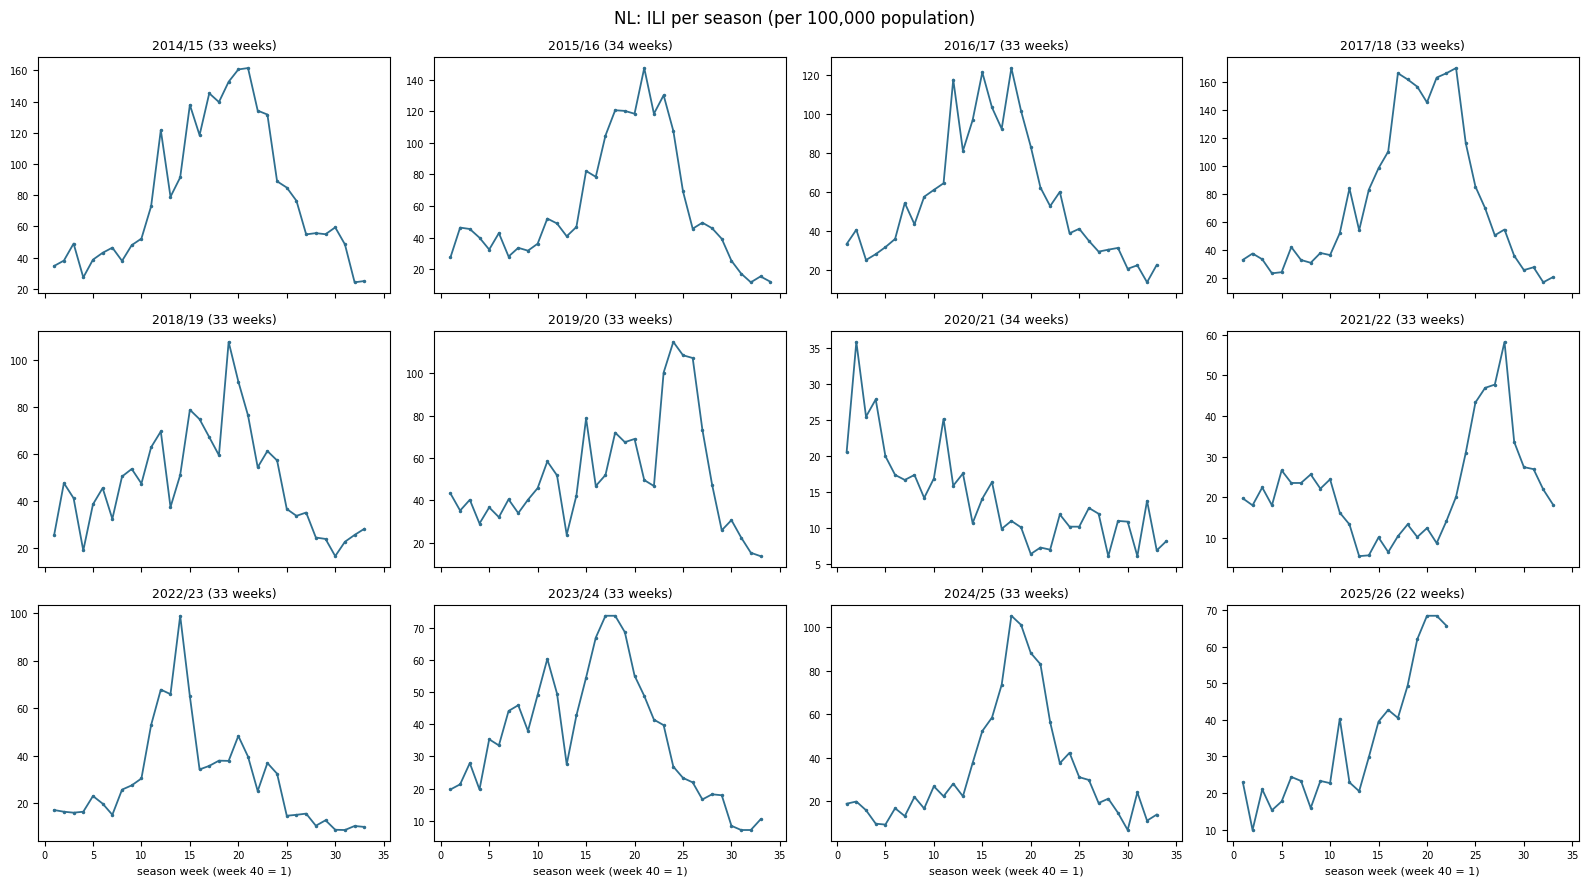

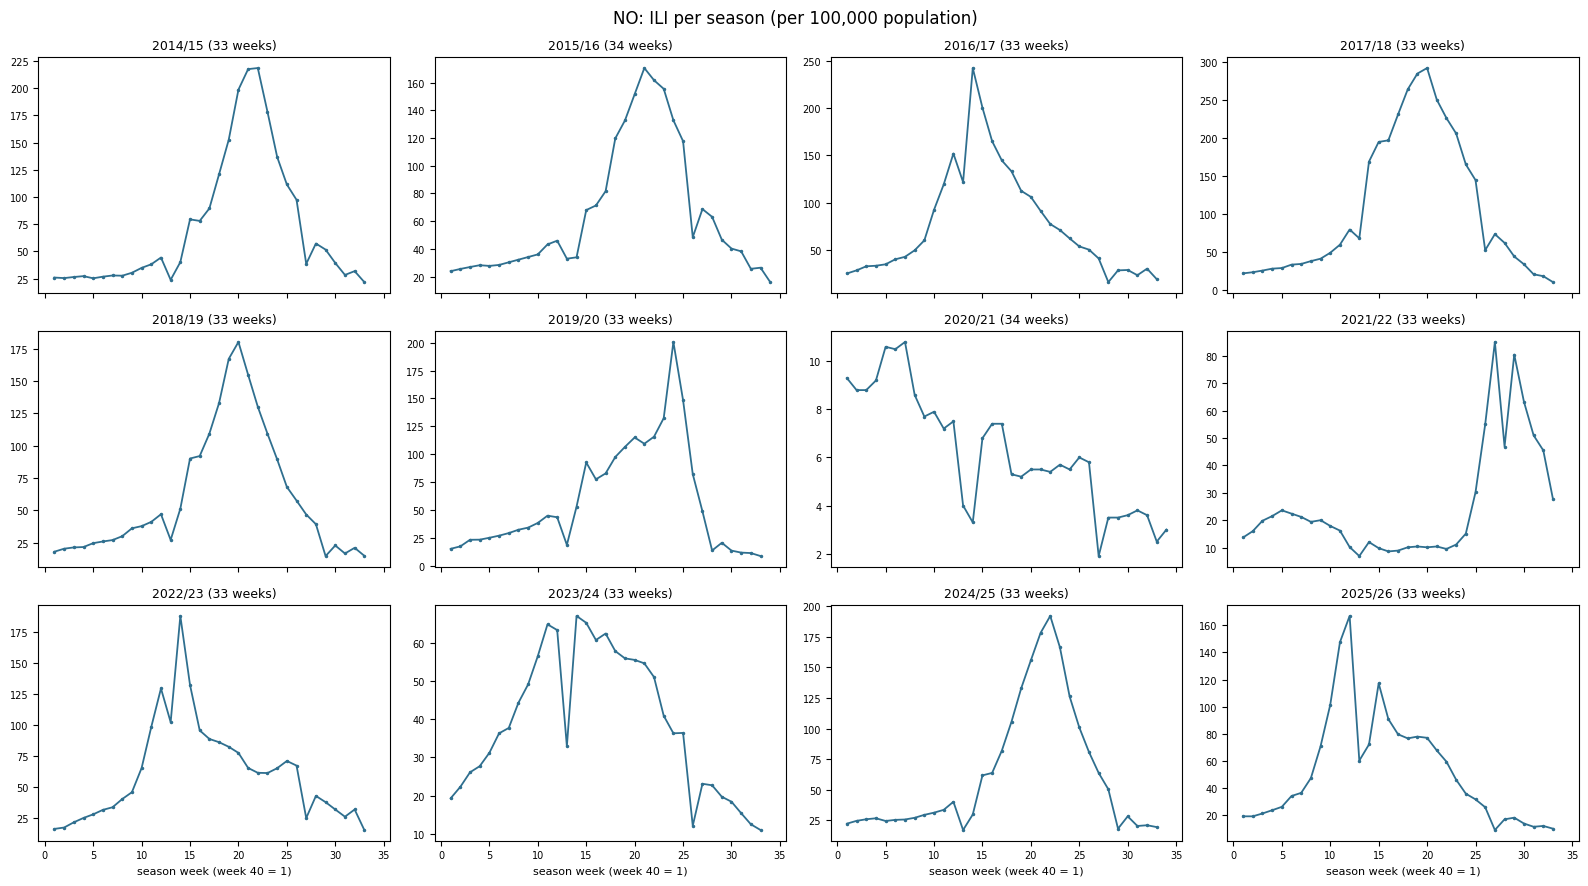

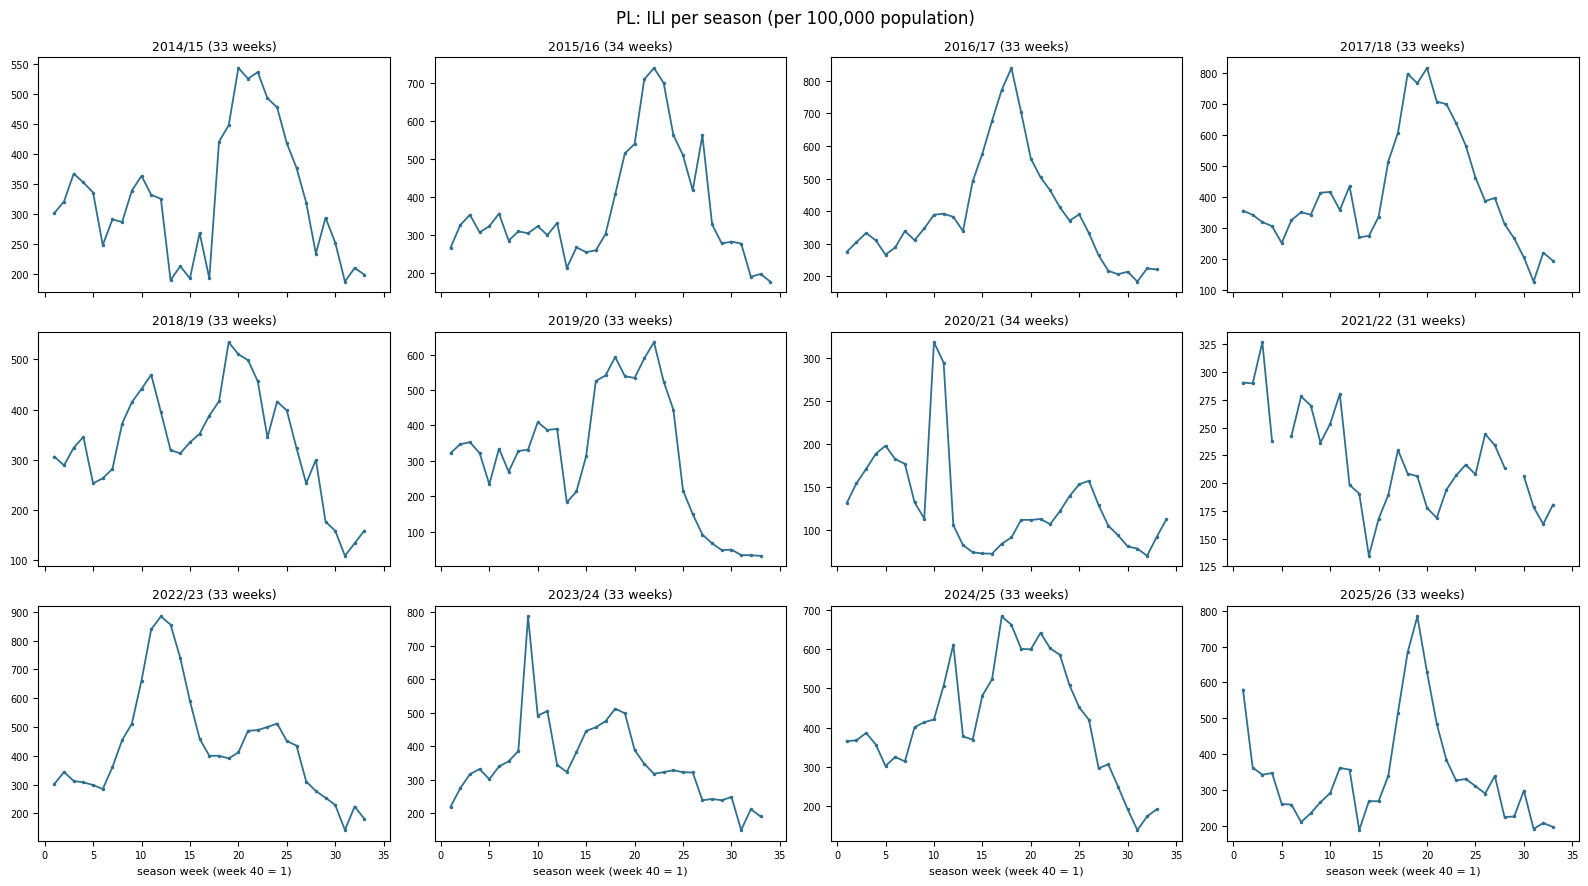

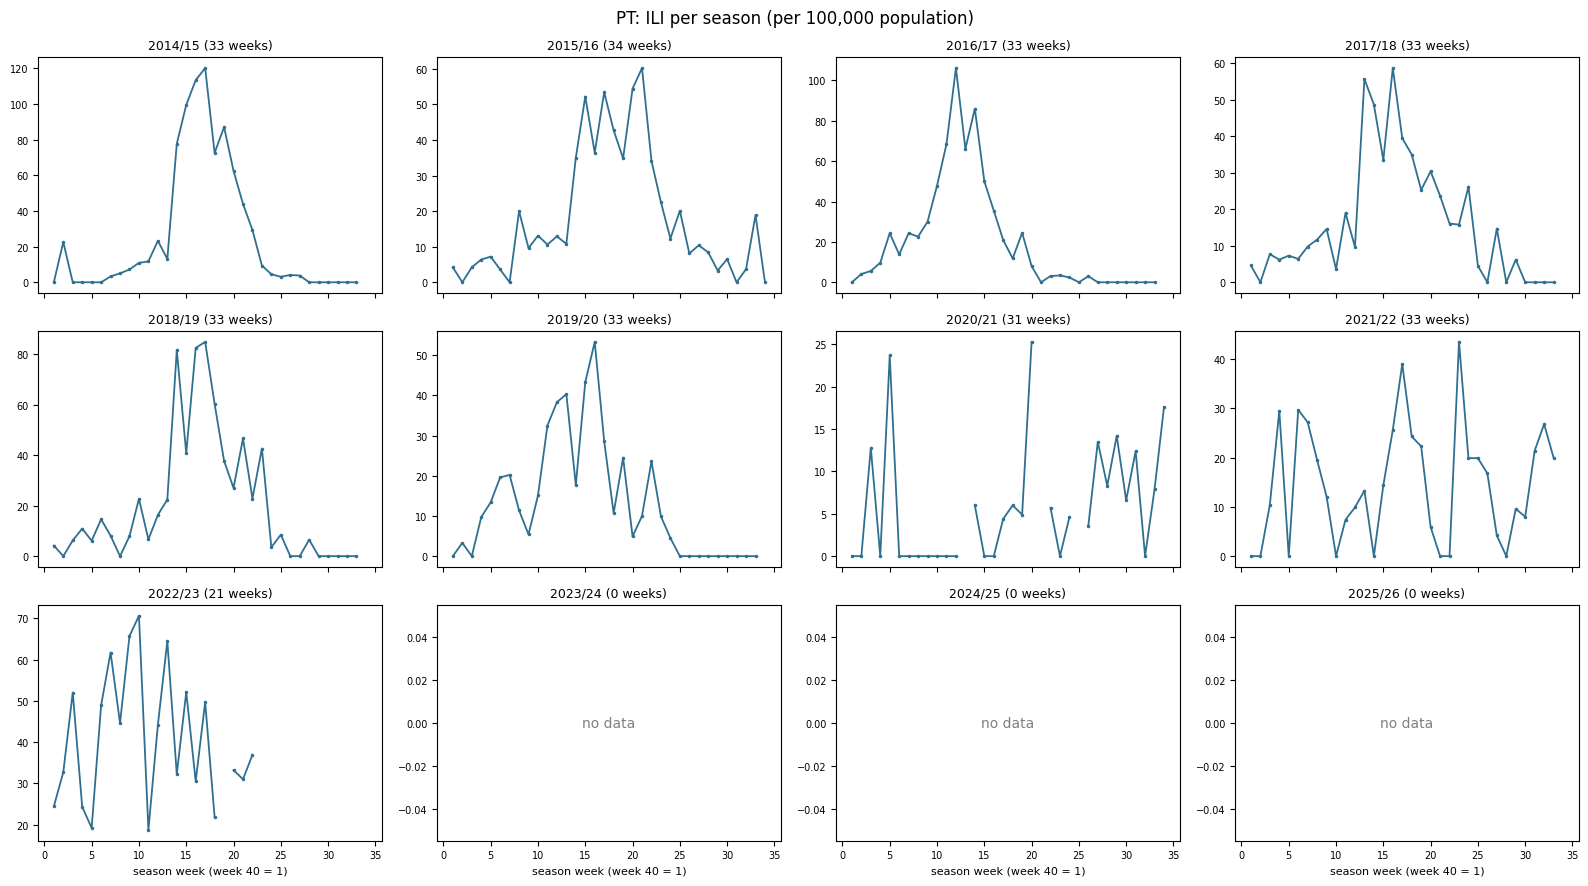

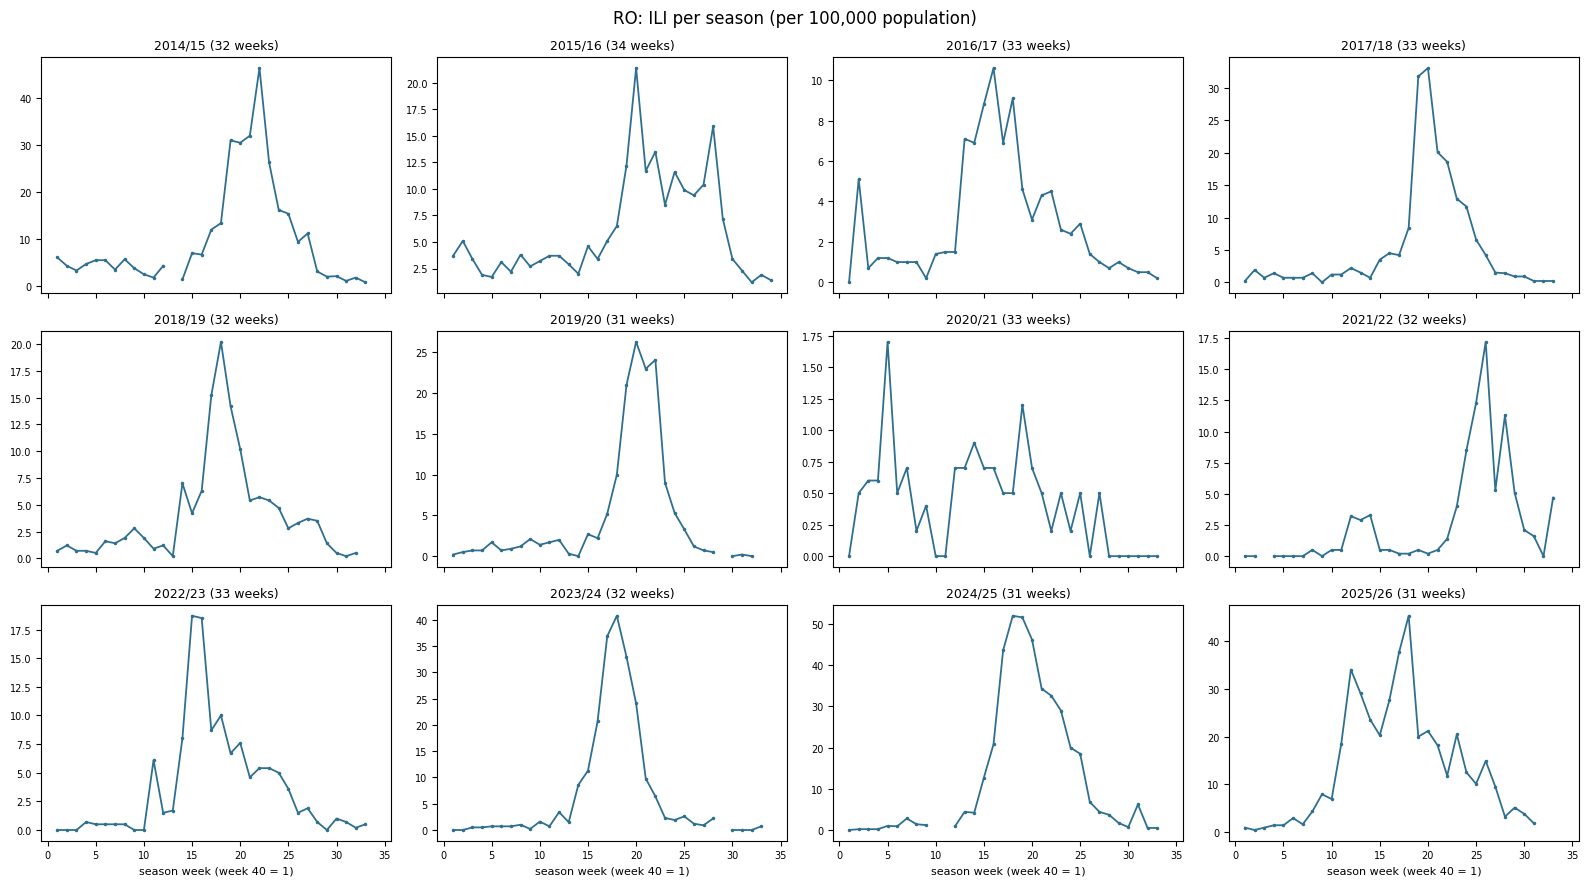

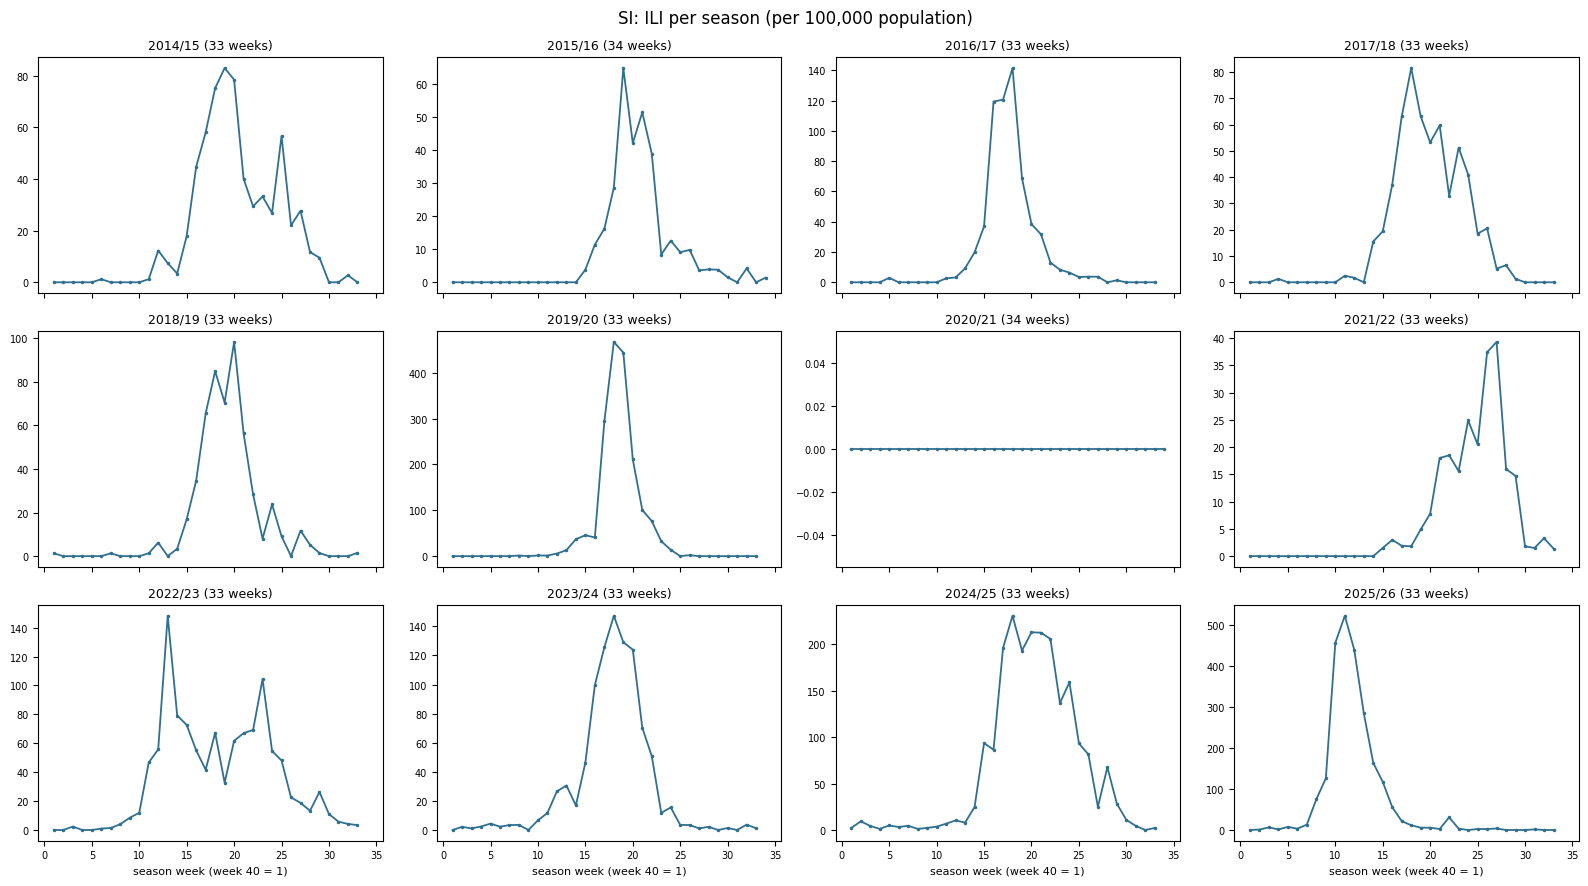

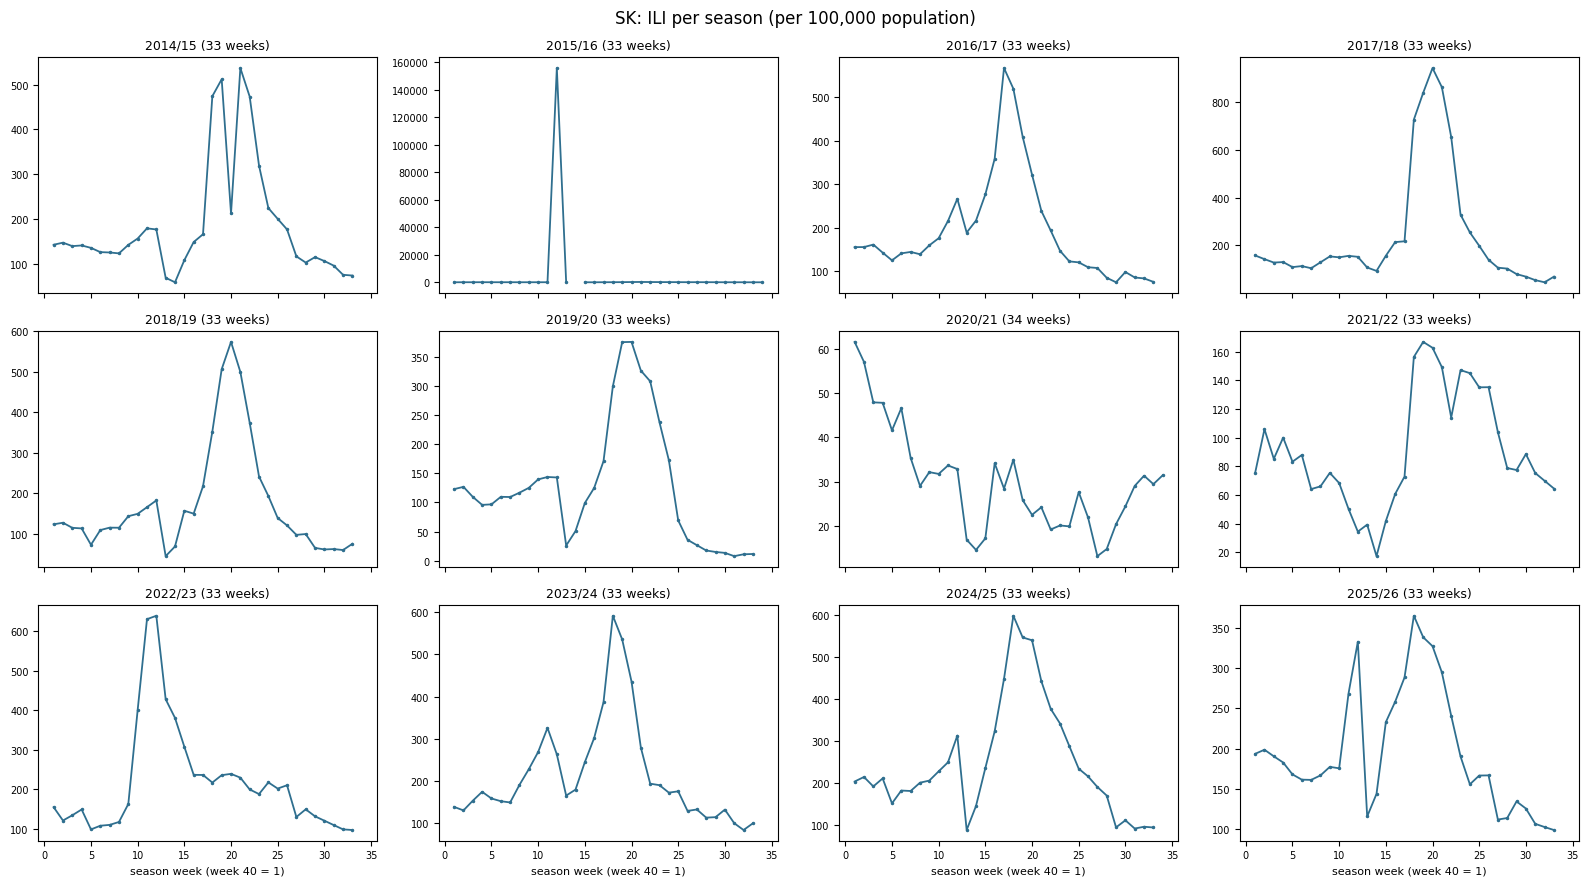

In [19]:
SEASONS = list(finished.columns)


def plot_country_seasons(country):
    d = data[data["country_code"] == country]
    ncols = 4
    nrows = -(-len(SEASONS) // ncols)    # rounded up: one panel per season
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows), sharex=True, squeeze=False)
    for ax, season in zip(axes.flat, SEASONS):
        s = (d[d["season"] == season]
             .set_index("season_week")["value"]
             .reindex(range(1, MAX_SEASON_WEEKS + 1)))
        ax.plot(s.index, s.values, color="#2F6F8F", linewidth=1.3, marker=".", markersize=3)
        ax.set_title(f"{season} ({s.count()} weeks)", fontsize=9)
        ax.tick_params(labelsize=7)
        if s.count() == 0:
            ax.text(0.5, 0.5, "no data", ha="center", va="center", transform=ax.transAxes, color="grey")
    for ax in axes.flat[len(SEASONS):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("season week (week 40 = 1)", fontsize=8)
    fig.suptitle(f"{country}: {TARGET} per season ({d['unit'].iloc[0]})", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"seasons_{country}.png", dpi=110)
    plt.show()


for country in sorted(data["country_code"].unique()):
    plot_country_seasons(country)

## 5. Data quality

### Negative values and zeros
Only countries with at least one negative value or zero.

In [20]:
values = pd.DataFrame({
    "rows": data.groupby("country_code").size(),
    "negative": (data["value"] < 0).groupby(data["country_code"]).sum(),
    "zeros": (data["value"] == 0).groupby(data["country_code"]).sum(),
})
values["share_zeros"] = (values["zeros"] / values["rows"]).round(2)

values[values[["negative", "zeros"]].sum(axis=1) > 0].sort_values("share_zeros", ascending=False)

,rows,negative,zeros,share_zeros
country_code,,,,
SI,630,0,355,0.56
PT,435,0,191,0.44
RO,603,0,193,0.32
LV,403,0,77,0.19
LU,505,0,84,0.17
LT,616,0,90,0.15
HR,430,0,66,0.15
CY,242,0,30,0.12
GB-WLS,338,0,18,0.05


### Missing weeks

In [21]:
last_season = finished.columns[-1]
last_date = pd.to_datetime(f"{int(last_season[:4]) + 1}-W{SEASON_END}-7", format="%G-W%V-%u")
all_weeks = pd.date_range(first_date, last_date, freq="7D")

full = (data.pivot(index="date", columns="country_code", values="value")
        .reindex(all_weeks)
        .rename_axis("date")
        .melt(ignore_index=False, value_name="value")
        .reset_index())
full = add_season(full)

missing_season = (full.assign(missing=full["value"].isna())
                  .pivot_table(index="country_code", columns="season", values="missing", aggfunc="sum")
                  .astype(int))
missing_season.to_csv(OUT_DIR / "missing_weeks_per_season.csv")

missing_season

season,2014/15,2015/16,2016/17,2017/18,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25,2025/26
country_code,,,,,,,,,,,,
AT,7,8,6,5,8,7,11,6,7,6,6,6
BE,0,0,0,0,0,0,0,0,0,0,0,0
CH,0,0,0,0,0,9,4,0,0,0,0,0
CY,0,0,1,1,0,33,34,33,33,33,33,33
CZ,0,0,0,0,0,0,0,0,0,0,0,0
DK,1,0,1,0,1,1,0,0,0,0,0,0
EE,0,0,0,0,0,0,0,0,0,0,2,0
ES,0,0,0,0,0,0,34,33,33,0,0,0
FI,32,2,1,0,1,1,34,0,0,0,0,0


### Sudden spikes

A week is a **spike** if it is more than 2 times higher than every week in the 4 weeks before and after it
(and above 10). Spikes can be real, but are often reporting errors. Weeks without a reported week before and
after cannot be checked. The same rule is used in the preprocessing.

In [22]:
SPIKE_WINDOW = 4
SPIKE_RATIO = 2
SPIKE_MIN = 10


def find_spikes(d, window=SPIKE_WINDOW, ratio=SPIKE_RATIO, min_value=SPIKE_MIN):
    s = d.set_index("date")["value"].asfreq("7D")
    around = pd.concat([s.shift(k) for k in range(-window, window + 1) if k != 0], axis=1)
    highest_around = around.max(axis=1)
    has_neighbours = s.shift(1).notna() & s.shift(-1).notna()
    mask = (s > ratio * highest_around) & (s > min_value) & has_neighbours
    return pd.DataFrame({"value": s[mask], "highest_around": highest_around[mask]})


spikes = (pd.concat({c: find_spikes(d) for c, d in data.groupby("country_code")},
                    names=["country_code", "date"])
          .reset_index())
spikes["times_higher"] = (spikes["value"] / spikes["highest_around"]).round(1)
spikes = add_season(spikes)
spikes.to_csv(OUT_DIR / "spikes.csv", index=False)

(spikes[["country_code", "season", "date", "value", "highest_around", "times_higher"]]
 .sort_values("times_higher", ascending=False))

,country_code,season,date,value,highest_around,times_higher
1,LU,2016/17,2017-05-07,500.0,0.0,inf
6,PT,2014/15,2014-10-12,22.6,0.0,inf
10,SK,2015/16,2015-12-20,155763.0,141.6,1100.0
9,SK,NaN,2015-06-28,996.1,76.1,13.1
2,LU,2017/18,2017-11-05,1800.0,400.0,4.5
4,LU,2020/21,2021-03-21,2100.0,500.0,4.2
7,PT,2015/16,2016-05-15,18.9,6.5,2.9
3,LU,2020/21,2021-02-14,1400.0,500.0,2.8
8,SI,2025/26,2026-03-01,30.9,11.6,2.7
5,LU,NaN,2024-08-18,3300.0,1600.0,2.1


The 8 weeks before and after every spike:

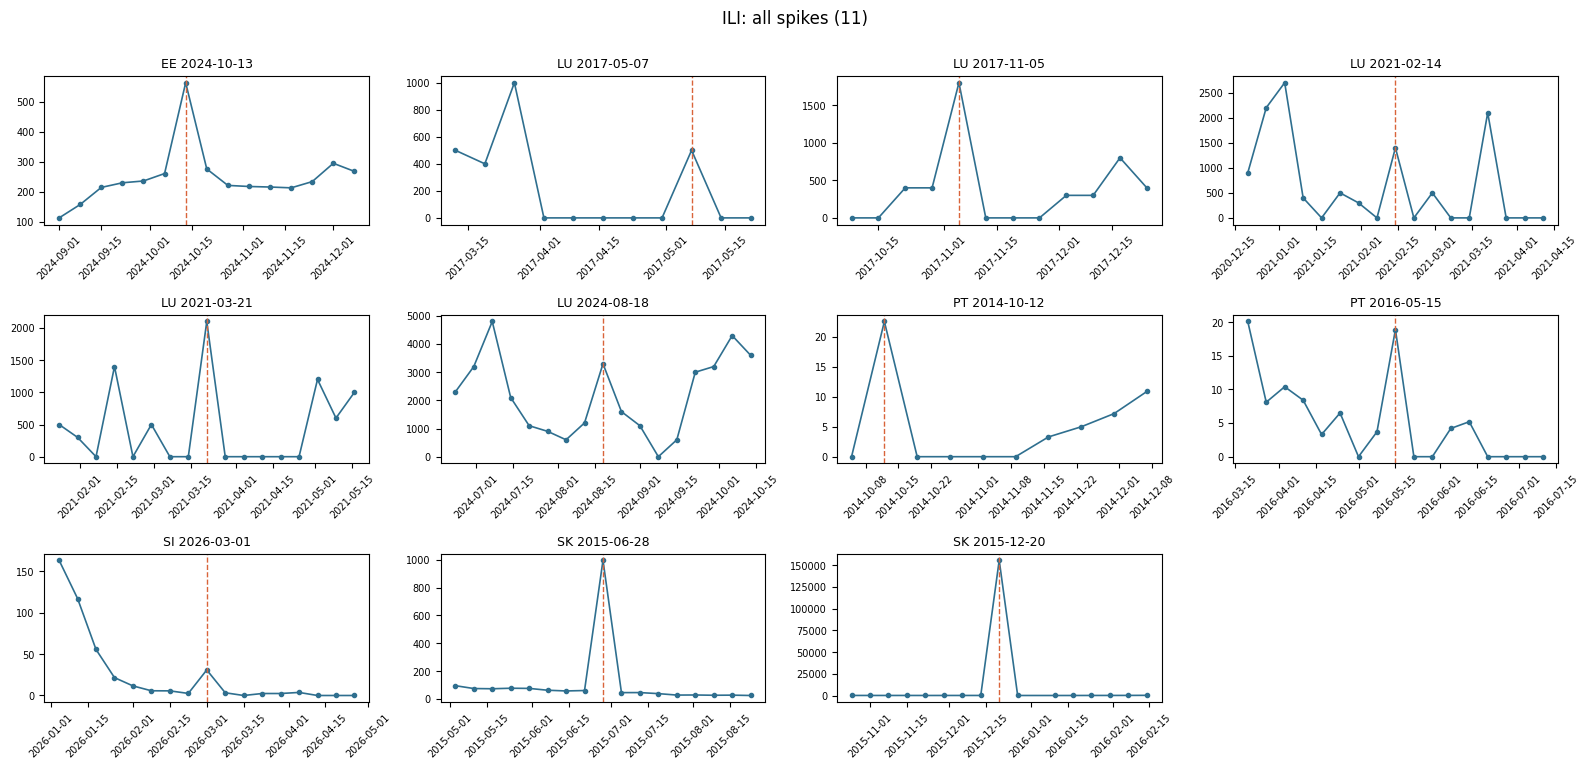

In [23]:
def plot_all_spikes(spikes, weeks=8, ncols=4):
    spikes = spikes.sort_values(["country_code", "date"])
    nrows = -(-len(spikes) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.6 * nrows), squeeze=False)
    for ax, (_, r) in zip(axes.flat, spikes.iterrows()):
        d = data[(data["country_code"] == r["country_code"])
                 & data["date"].between(r["date"] - pd.Timedelta(weeks=weeks),
                                        r["date"] + pd.Timedelta(weeks=weeks))]
        ax.plot(d["date"], d["value"], color="#2F6F8F", marker=".", linewidth=1.2)
        ax.axvline(r["date"], color="#D9643A", linestyle="--", linewidth=1)
        ax.set_title(f"{r['country_code']} {r['date'].date()}", fontsize=9)
        ax.tick_params(labelsize=7)
        ax.tick_params(axis="x", rotation=45)
    for ax in axes.flat[len(spikes):]:
        ax.set_visible(False)
    fig.suptitle(f"{TARGET}: all spikes ({len(spikes)})", fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    fig.savefig(FIG_DIR / "spikes.png", dpi=110)
    plt.show()


plot_all_spikes(spikes)

## 6. Influenza positivity

Positivity = % of tested samples positive for influenza, in primary care (where ILI is measured).
Checked: which countries have it and since when, how often there are fewer than 10 tests,
and whether ILI and positivity move together. Switzerland and the UK have no ERVISS positivity.

In [24]:
flu = pos[(pos["pathogen"] == "Influenza") & (pos["setting"] == "primary care")]

pos_overview = flu.groupby("country_code").agg(
    first=("date", "min"),
    last=("date", "max"),
    weeks=("value", "count"),
    low_tests=("tests", lambda t: (t < MIN_TESTS).sum()),
)
pos_overview["first"] = pos_overview["first"].dt.date
pos_overview["last"] = pos_overview["last"].dt.date
pos_overview["share_low_tests"] = (pos_overview["low_tests"] / pos_overview["weeks"]).round(2)
pos_overview.to_csv(OUT_DIR / "positivity_overview.csv")

pos_overview.sort_values("share_low_tests", ascending=False)

,first,last,weeks,low_tests,share_low_tests
country_code,,,,,
LV,2014-12-28,2023-06-25,99,74,0.75
FI,2014-08-17,2023-12-17,352,261,0.74
NL,2014-06-22,2026-10-25,604,284,0.47
PT,2014-10-05,2026-10-25,441,202,0.46
SI,2014-06-22,2026-10-25,553,243,0.44
BE,2014-10-05,2026-10-18,393,166,0.42
EE,2014-09-07,2026-10-25,517,202,0.39
PL,2014-09-21,2026-10-25,420,164,0.39
HR,2019-11-17,2022-10-02,73,24,0.33


Countries with ILI data but **no** positivity:

In [25]:
sorted(set(data["country_code"]) - set(flu["country_code"]))

['CH', 'GB', 'GB-ENG', 'GB-NIR', 'GB-SCT', 'GB-WLS', 'IS']

ILI and positivity together

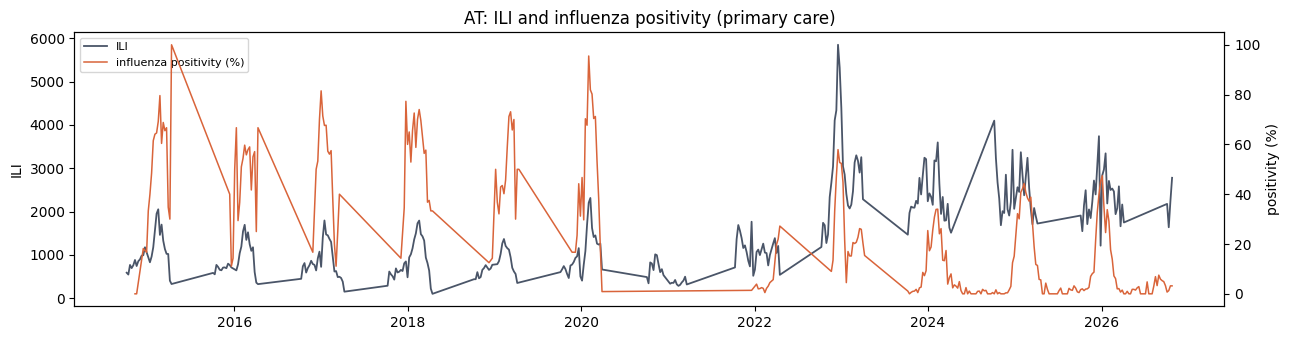

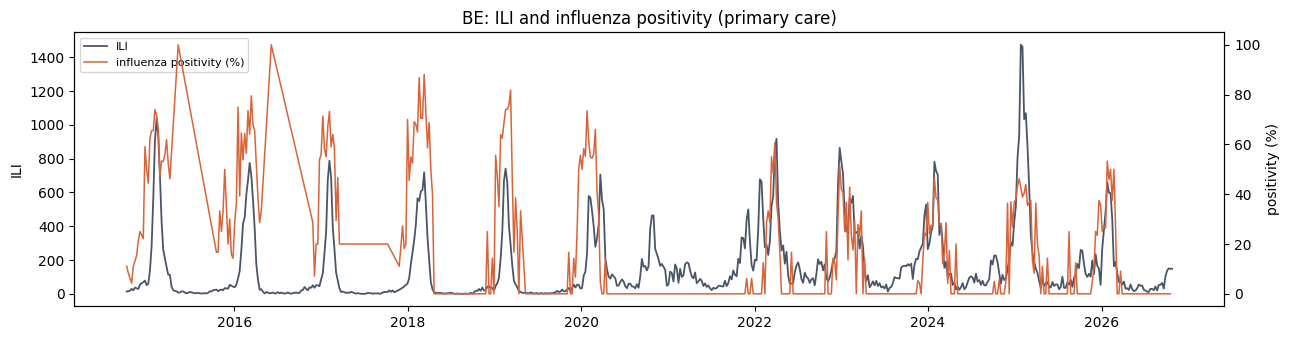

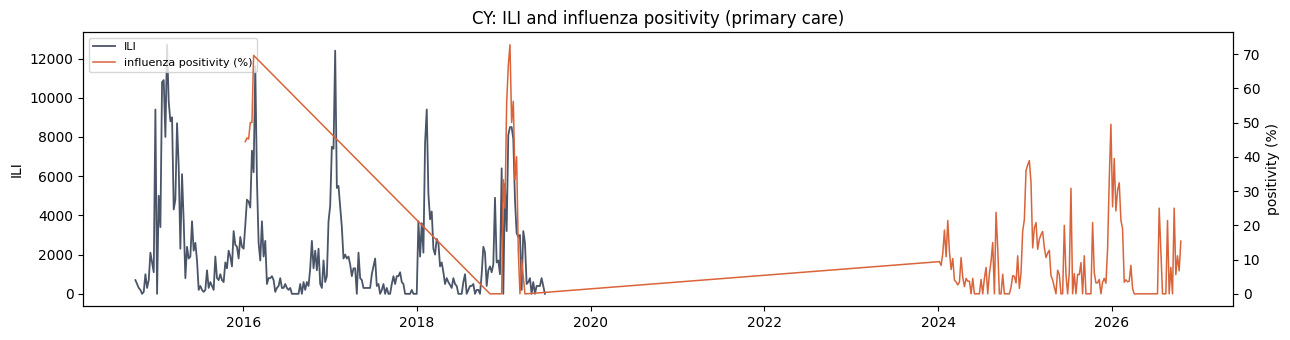

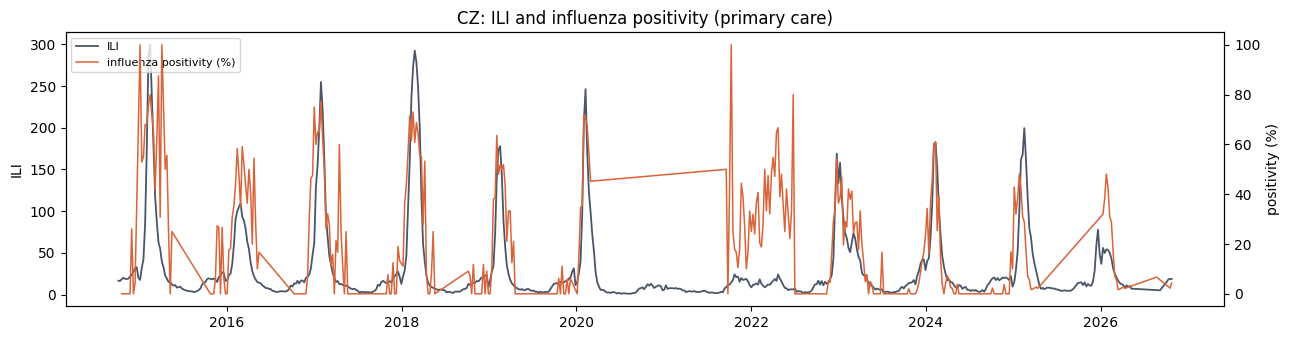

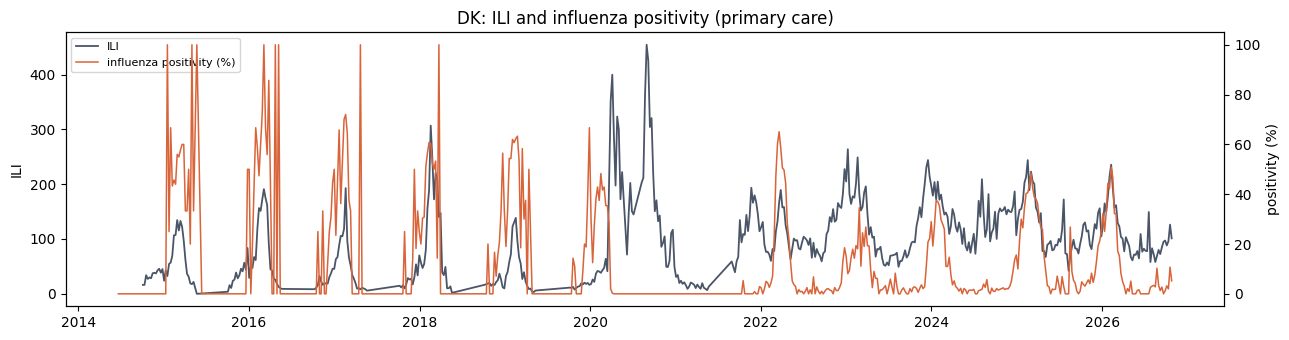

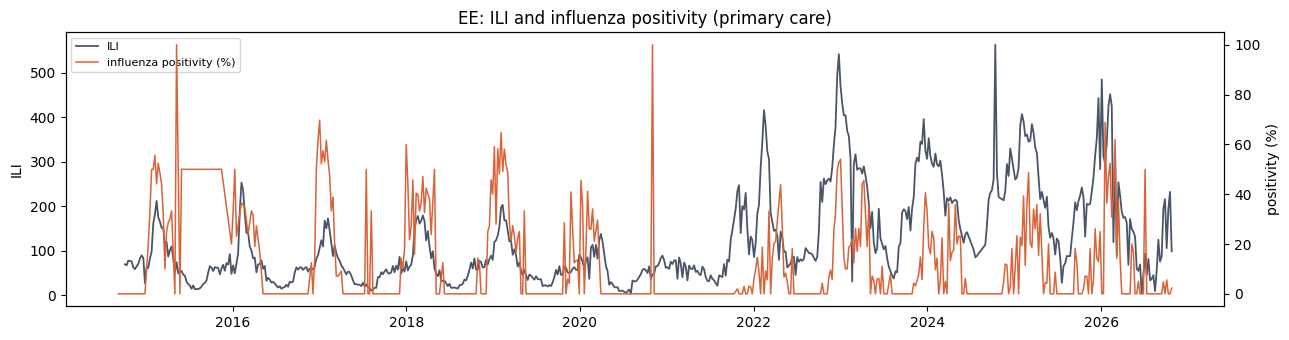

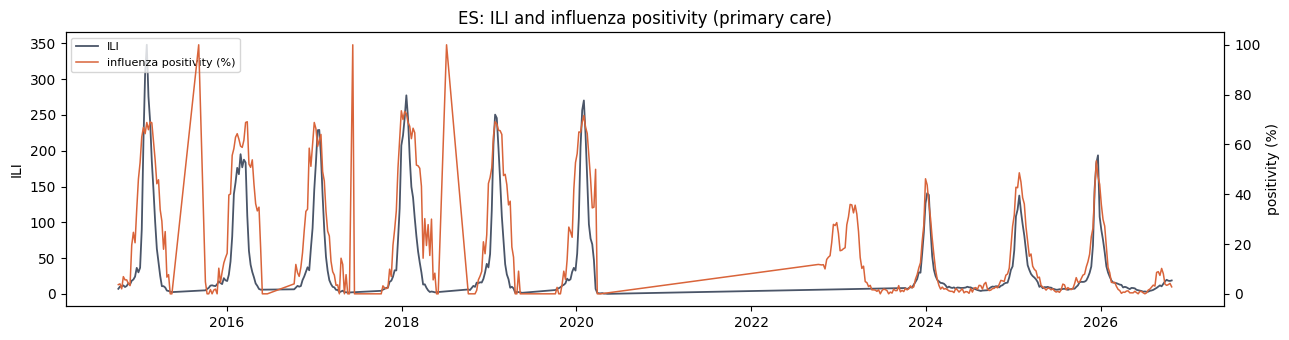

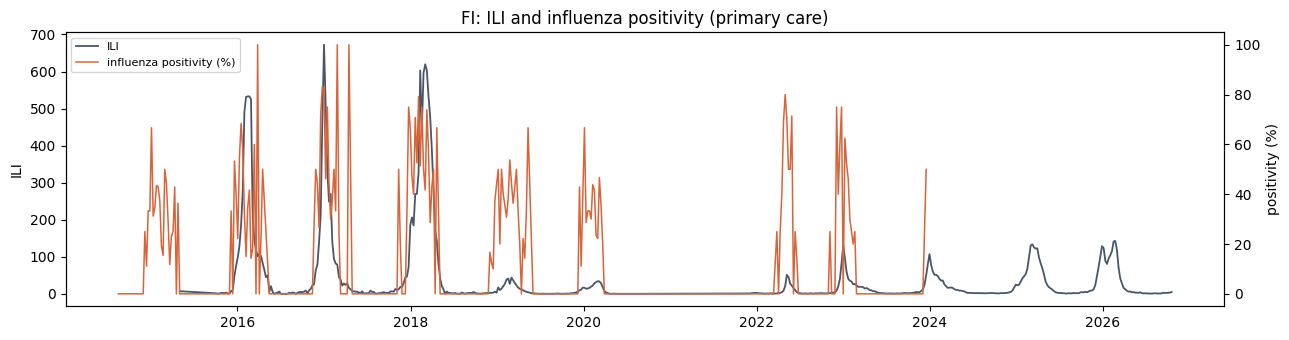

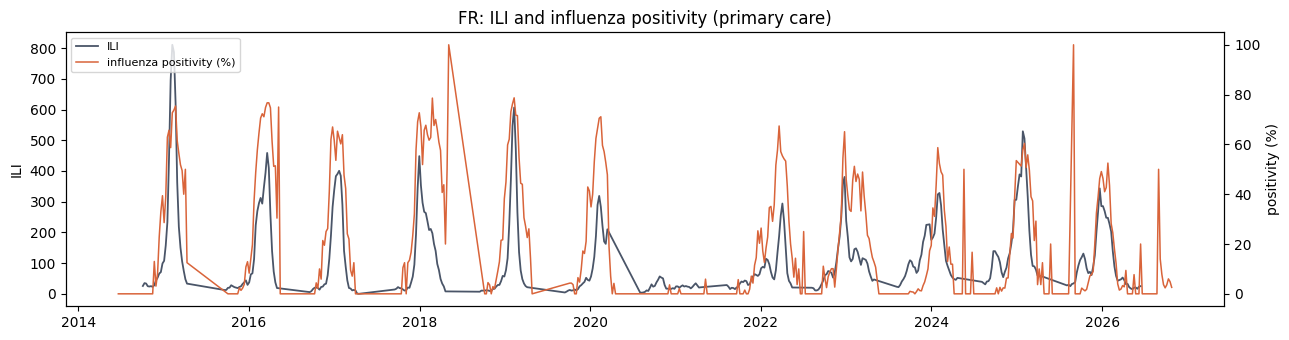

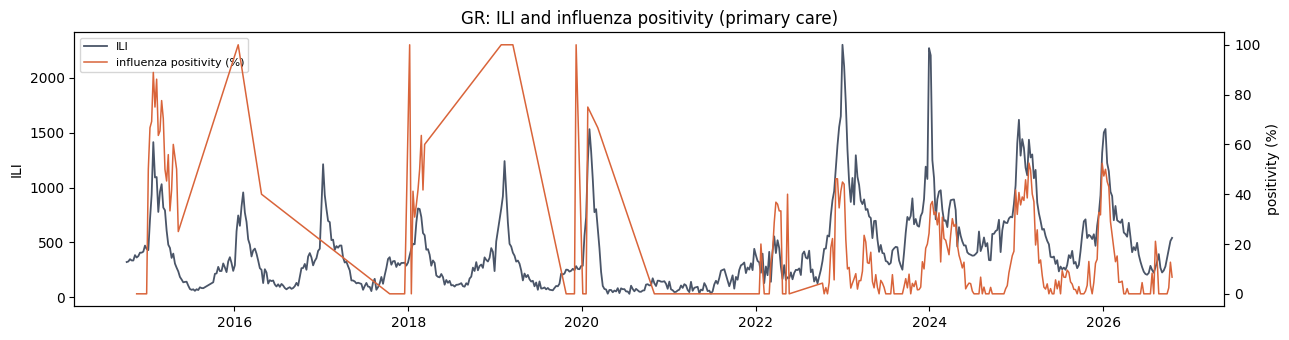

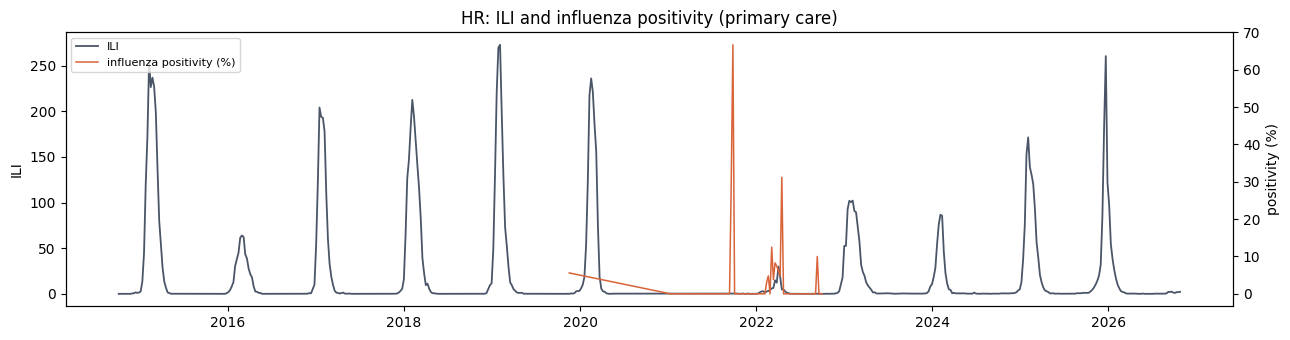

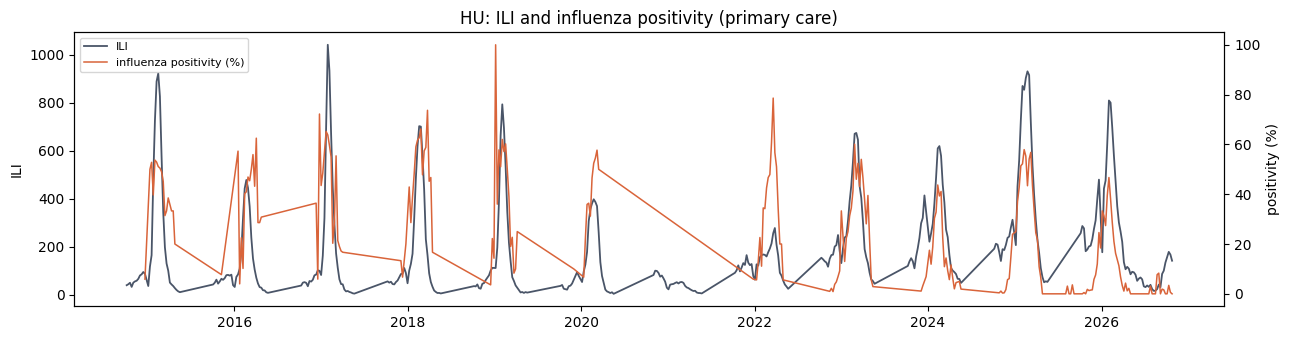

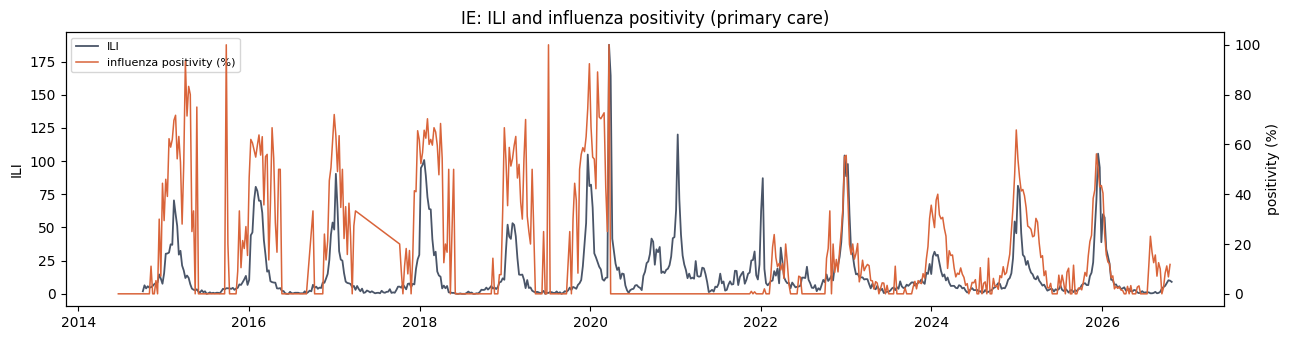

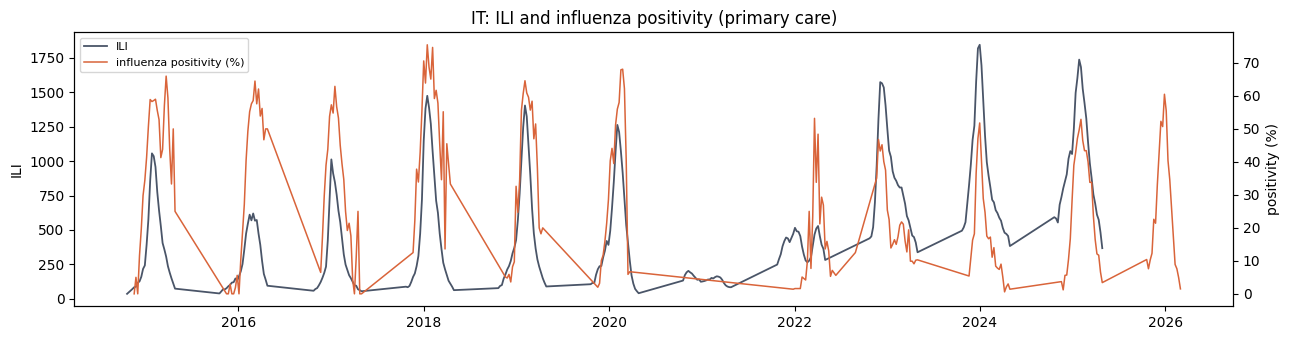

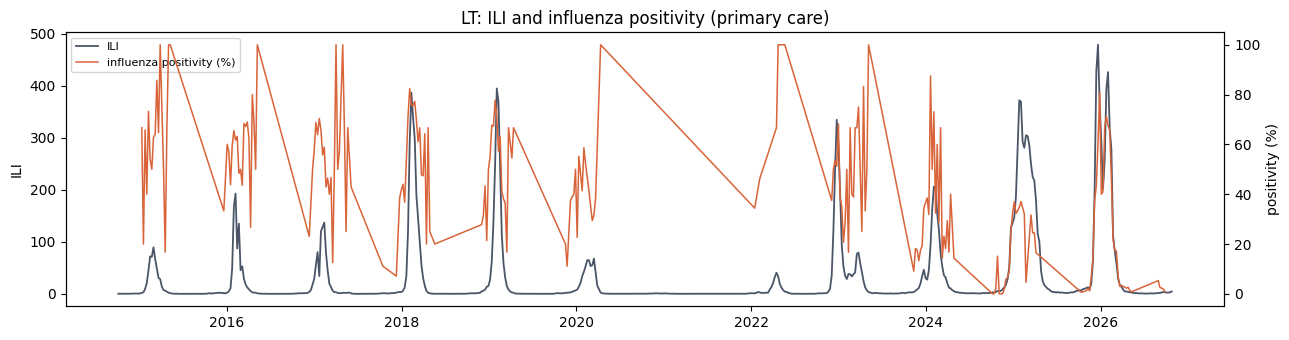

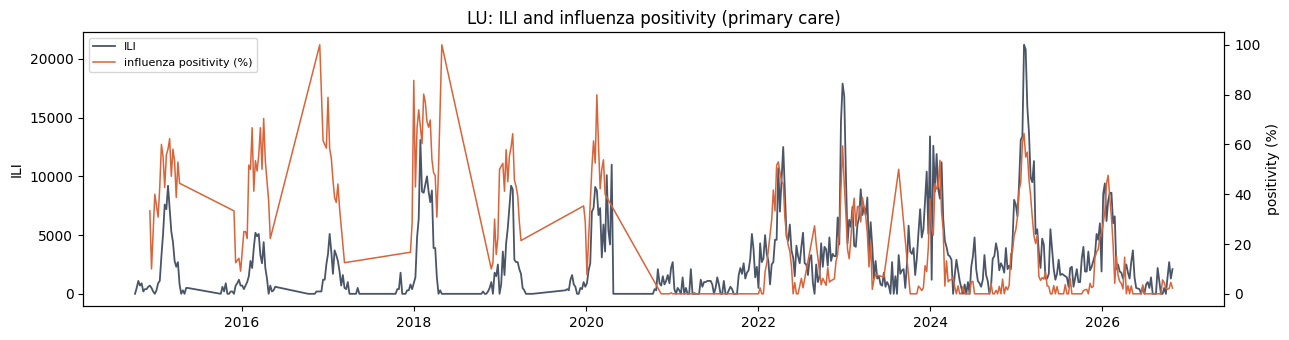

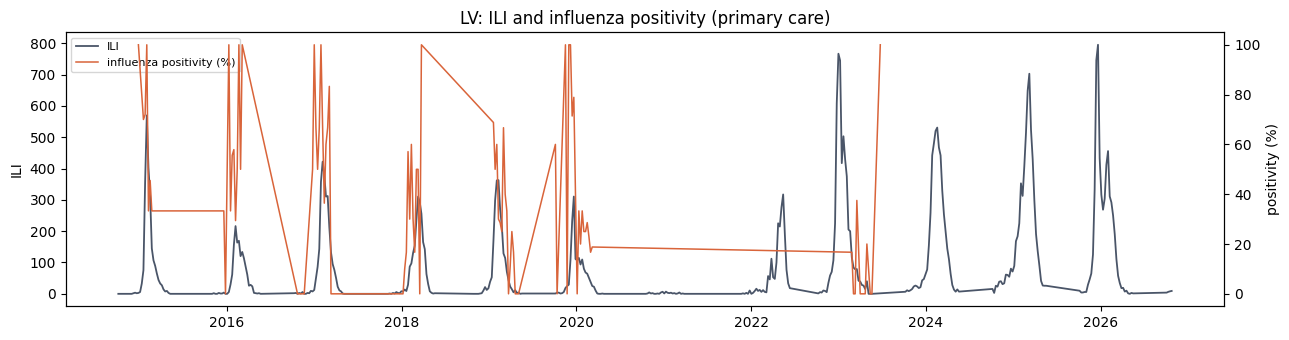

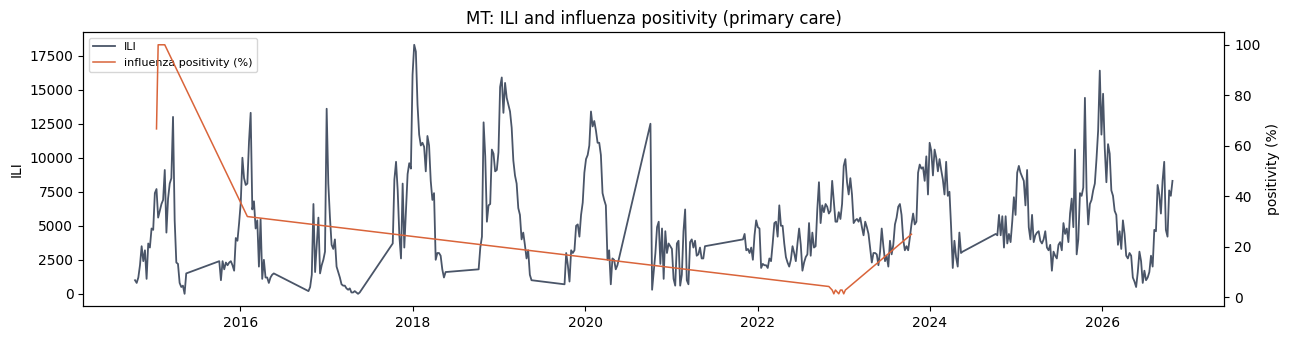

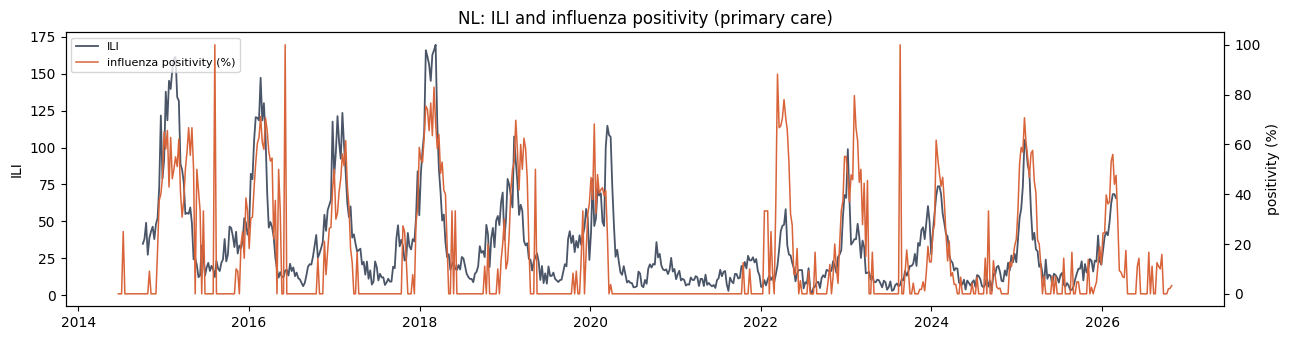

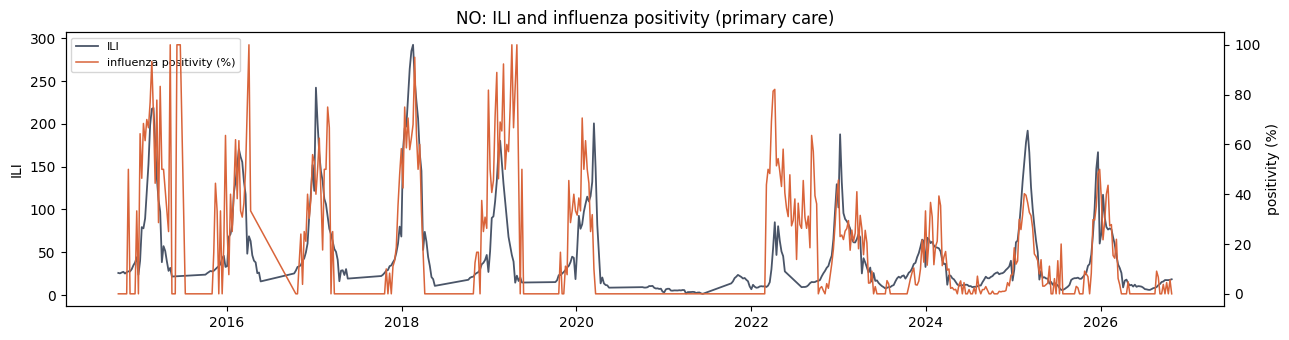

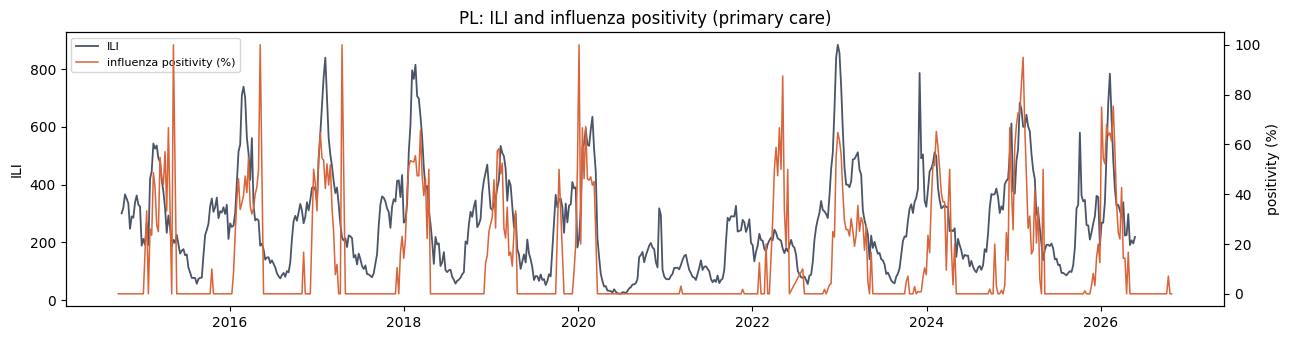

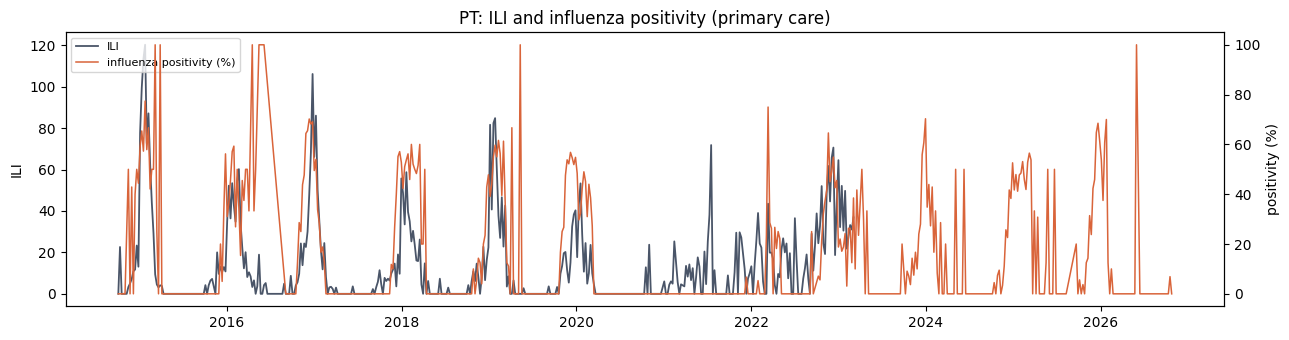

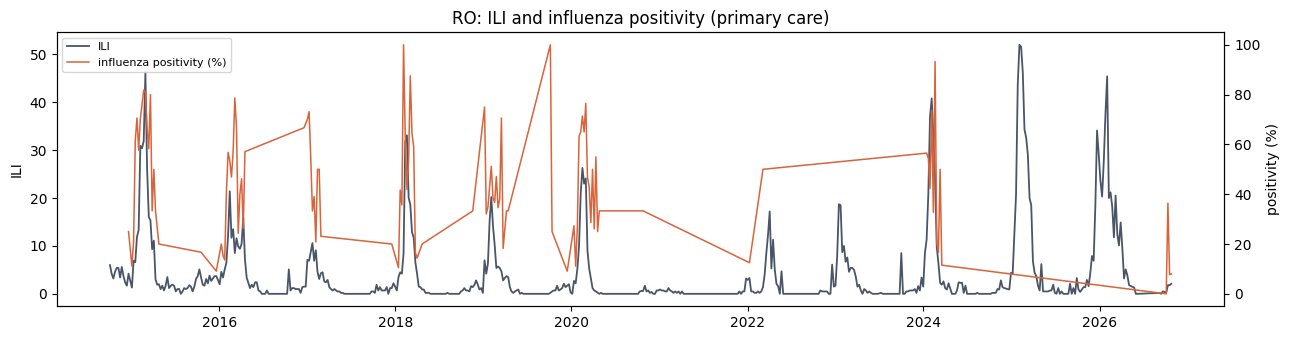

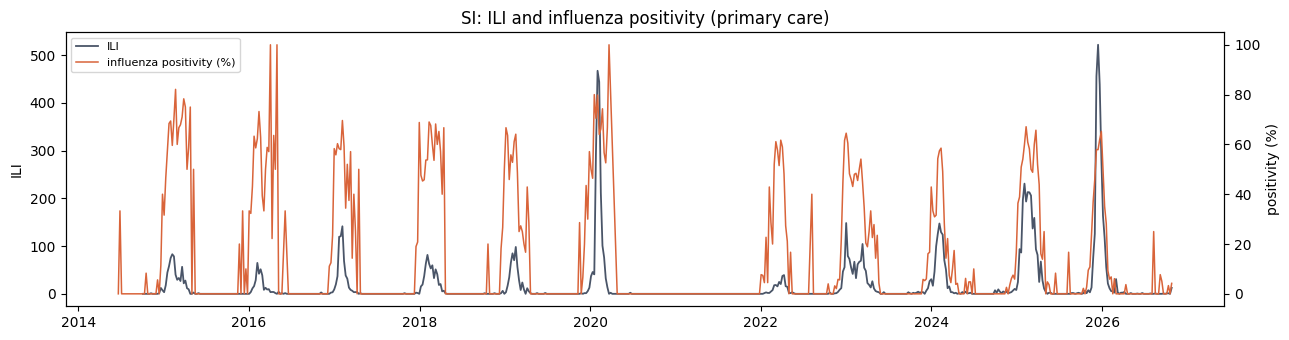

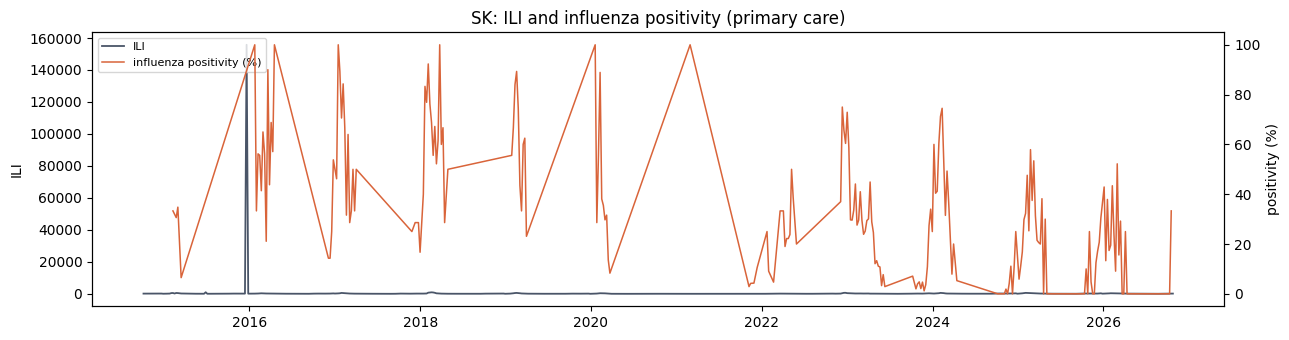

In [26]:
def plot_positivity(country):
    a = data[data["country_code"] == country]
    p = flu[flu["country_code"] == country]
    fig, ax = plt.subplots(figsize=(13, 3.5))
    ax.plot(a["date"], a["value"], color="#4A5568", linewidth=1.3, label=TARGET)
    ax.set_ylabel(TARGET)
    ax2 = ax.twinx()
    ax2.plot(p["date"], p["value"], color="#D9643A", linewidth=1.1, label="influenza positivity (%)")
    ax2.set_ylabel("positivity (%)")
    ax.set_title(f"{country}: {TARGET} and influenza positivity (primary care)")
    lines = ax.get_lines() + ax2.get_lines()
    ax.legend(lines, [l.get_label() for l in lines], loc="upper left", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"positivity_{country}.png", dpi=130)
    plt.show()


for c in sorted(flu["country_code"].unique()):
    if c in data["country_code"].values:
        plot_positivity(c)

## 7. Summary per country

One row per country with the results of the sections above.

In [27]:
countries = data.groupby("country_code").agg(
    country=("country", "first"),
    source=("source", "first"),
    first_week=("date", "min"),
    last_week=("date", "max"),
)
countries["first_week"] = countries["first_week"].dt.date
countries["last_week"] = countries["last_week"].dt.date

positivity = pos_overview[["first", "share_low_tests"]].rename(
    columns={"first": "positivity_from", "share_low_tests": "positivity_low_tests"})

summary = (countries
           .join(valid)
           .join(missing_season.sum(axis=1).rename("missing_weeks"))
           .join(values["zeros"])
           .join(spikes.groupby("country_code").size().rename("spikes"))
           .join(positivity))
summary["spikes"] = summary["spikes"].fillna(0).astype(int)
summary.insert(summary.columns.get_loc("positivity_from"), "has_positivity", summary["positivity_from"].notna())
summary[["positivity_from", "positivity_low_tests"]] = (
    summary[["positivity_from", "positivity_low_tests"]].astype(object).fillna("/"))

summary.to_csv(OUT_DIR / "data_summary.csv")

summary.sort_values("percent_valid", ascending=False)

,country,source,first_week,last_week,valid_seasons,total_seasons,percent_valid,missing_weeks,zeros,spikes,has_positivity,positivity_from,positivity_low_tests
country_code,,,,,,,,,,,,,
AT,Austria,ERVISS,2014-10-05,2026-10-25,12,12,100.0,83,0,0,True,2014-11-09,0.09
BE,Belgium,ERVISS,2014-10-05,2026-10-25,12,12,100.0,0,13,0,True,2014-10-05,0.42
CH,Switzerland,FluID,2014-10-05,2026-10-25,12,12,100.0,13,8,0,False,/,/
CZ,Czechia,ERVISS,2014-10-05,2026-10-25,12,12,100.0,0,0,0,True,2014-10-19,0.22
EE,Estonia,ERVISS,2014-10-05,2026-10-25,12,12,100.0,2,0,1,True,2014-09-07,0.39
DK,Denmark,ERVISS,2014-10-05,2026-10-25,12,12,100.0,4,1,0,True,2014-06-22,0.28
GR,Greece,ERVISS,2014-10-05,2026-10-18,12,12,100.0,1,0,0,True,2014-11-16,0.18
FR,France,ERVISS,2014-10-05,2026-06-14,12,12,100.0,50,0,0,True,2014-06-22,0.18
MT,Malta,ERVISS,2014-10-12,2026-10-25,12,12,100.0,8,2,0,True,2015-01-11,0.29
